# State Space Models with `dynestyx` and `numpyro_forecast`

*This is the advanced `dynestyx` example. Start with [getting started with `dynestyx` state space models](dynestyx_getting_started.html), which introduces the building block on the ARMA and BART examples. This notebook goes further: filtering versus smoothing, the cost of a gradient, variational inference and backtesting.*

In this notebook we write a [`dynestyx`](https://github.com/BasisResearch/dynestyx) state space model as a `numpyro_forecast` model. We then fit it, forecast with it and backtest it with the drivers of the package, without changing them.

`dynestyx` is a probabilistic programming library for dynamical systems built on NumPyro. Its central object is a `DynamicalModel`, which bundles an initial condition, a state evolution and an observation model. Its primitive, `dsx.sample`, is interpreted by effect handlers. A `Filter` or a `Smoother` integrates the latent path out with a filtering algorithm and adds the marginal log likelihood, or its estimate, to the NumPyro trace. The Kalman filter does this exactly for linear-Gaussian models. The ensemble, extended and unscented Kalman filters and the particle filters do it approximately. A `LatentPathBuilder` samples the path explicitly. A `Simulator` rolls the model forward in time.

`numpyro_forecast` is a forecasting workflow layer. A model is a plain function `(covariates, data=None)` built from model building blocks that register the `"obs"` and `"forecast"` sites. The drivers ([`forecast`](../../reference/predictive.forecast.html), [`predict_in_sample`](../../reference/predictive.predict_in_sample.html), [`to_datatree`](../../reference/convert.to_datatree.html), [`backtest`](../../reference/evaluate.backtest.html) and the metrics) read those sites by name.

The two libraries compose at the trace level. The [`state_space`](../../reference/contrib.dynestyx.state_space.html) building block of `numpyro_forecast.contrib.dynestyx` connects them. The `dynestyx` handler goes around each call that runs the model, so the same model function serves every inference strategy. Integrating the latent path out (a `Smoother`) or sampling it explicitly (a `LatentPathBuilder`) is a change of the handler around the call.

We proceed as follows:

1. **Prepare Notebook.** We load the libraries and set the configuration.
2. **The Building Block.** We explain the contract of `state_space`.
3. **Local Level Model.** We fit the same model three times: in the direct form of the package, with `dynestyx` sampling the path explicitly, and with `dynestyx` integrating it out with a Kalman smoother. We compare posteriors, sampler efficiency, forecasts, in-sample fits and the reconstructed latent level.
4. **Seasonal Regression Model.** We add a seasonal regression through the covariates, fit it with SVI and run the expanding-window backtest of the package on the `dynestyx` model, in and out of sample. This is the evaluation direction that the [design document](https://github.com/juanitorduz/numpyro_forecast/blob/main/docs/dev/dynestyx_integration_design.md) of this integration proposes.
5. **Conclusion.** We summarize the findings, the limitations and our recommendations.

## Prepare Notebook

We load the necessary libraries and set the notebook's configuration.

In [1]:
import time
import warnings
from collections.abc import Callable
from contextlib import AbstractContextManager, nullcontext
from functools import partial
from typing import Any

import arviz as az
import dynestyx as dsx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import numpyro
import numpyro.distributions as dist
import polars as pl
import xarray as xr
from dynestyx import (
    DiscreteTimeSimulator,
    DynamicalModel,
    Filter,
    LatentPathBuilder,
    Simulator,
    Smoother,
)
from dynestyx.configs import KFConfig, KFSmootherConfig
from jax import random
from numpyro.infer import MCMC, NUTS, SVI, Predictive, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal
from numpyro.infer.reparam import LocScaleReparam
from numpyro.infer.util import log_density
from numpyro.optim import Adam

from numpyro_forecast import (
    Horizon,
    backtest,
    draw_posterior,
    eval_coverage,
    eval_crps,
    eval_mae,
    eval_rmse,
    forecast,
    innovations,
    predict,
    predict_in_sample,
    predictions_to_datatree,
    results_to_dataframe,
    to_datatree,
)
from numpyro_forecast.contrib.dynestyx import state_space
from numpyro_forecast.features import fourier_features
from numpyro_forecast.typing import Array, ForecastModel

# arviz-plots warns whenever `aes` maps `alpha`, even to `["prob"]` as the band plots below do
warnings.filterwarnings(
    "ignore", message="When multiple credible intervals are plotted", category=UserWarning
)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

numpyro.set_host_device_count(n=4)

rng_key = random.PRNGKey(seed=42)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

# the versions that produced the stored outputs
pl.DataFrame(
    {
        "package": ["dynestyx", "numpyro", "jax"],
        "version": [dsx.__version__, numpyro.__version__, jax.__version__],
    }
)

package,version
str,str
"""dynestyx""","""0.9.0"""
"""numpyro""","""0.22.0"""
"""jax""","""0.12.0.1"""


## The Building Block

[`state_space`](../../reference/contrib.dynestyx.state_space.html) takes the current call's [`Horizon`](../../reference/models.Horizon.html), a site name, the observed window `y` and a `dynestyx` `DynamicalModel`. It calls `dsx.sample` once on the step index $0, 1, \ldots$ as the time grid. The `dynestyx` handlers that are active around the call decide what that call does:

- **`Filter` or `Smoother`**: they compute the marginal log likelihood $\log p(y_{1:T} \mid \theta)$ of the window and register it as a NumPyro factor. The joint density that NUTS or SVI sees is then $p(\theta) \, p(y_{1:T} \mid \theta)$, with the latent path integrated out. The smoother also provides the smoothing distribution $p(x_t \mid y_{1:T}, \theta)$ of every in-window state, which the filter does not. It computes it with a backward pass after the forward filter, so a full smoother evaluation costs more than a filter evaluation. The marginal log likelihood comes from the forward pass alone, and the smoothed states are deterministic sites that NumPyro recomputes once per MCMC transition, not once per leapfrog step. The compiled gradient of the log density therefore costs the same under both handlers, because JAX drops the backward pass from it. We measure both costs in the Model Diagnostics section. This is a property of the current implementation, not a guarantee for every backend or model.
- **`LatentPathBuilder`**: it creates one sample site for the whole path and registers the joint density of states and observations as a factor. The sampler explores the path explicitly, as it does with the package's own [`innovations`](../../reference/models.innovations.html). The difference is that `dynestyx` builds the path, so non-Gaussian observation models and observations with missing values are available.
- **`Simulator`**: it rolls the conditioned state forward over the forecast horizon. We place it outside the handler of the fit when we call `forecast` or `to_datatree`.

The block has three modes, and `h.data` and `h.future` select them. The observations themselves come from the `y` argument, which the model slices from `covariates` (the series doubles as a covariate, the same contract as [`ssoe`](../../reference/models.ssoe.html)). This is what lets a model call without data still reach the observed window.

1. **Training** (`data` present, no horizon): the block runs `dsx.sample` under the active handler. The factor (and the path site, for the builder) enters the trace.
2. **Forecasting** (`covariates` longer than `data`): the `Simulator` around the call starts from the conditioned distribution of the state at the last observed step and rolls it forward. Under a `Filter` or a `Smoother` that is the filtering or smoothing distribution at the parameters of each posterior draw (the two coincide at the last step). Under a `LatentPathBuilder` it is the sampled final state, which inherits the mixing of the path. The block registers the horizon draws as the `"forecast"` site.
3. **In-sample predictive** (`data=None`): the block draws the in-window states from the posterior over the path (the smoothing distribution, or the explicit path). It samples one observation per step from the observation model and registers them as the `"obs"` site. `data=None` selects this mode; the observed window still reaches the model through the covariates. The in-sample predictive is a smoothing task, which is why a `Filter` raises in this mode.

The block owns the likelihood, so it also owns the two sites, like [`predict`](../../reference/models.predict.html). It returns a [`StateSpaceResult`](../../reference/contrib.dynestyx.StateSpaceResult.html) with the state draws of the current mode, `x_future` over the horizon and `x_in_sample` over the window, so that a model can register its latent level.

Three details of the implementation matter for correctness:

- **The anchor.** The prediction grid starts at the last observed step, `t_obs - 1`, and the block drops the first returned row. The simulator's first predicted state is the conditioned draw at the first prediction time without a transition, so this anchor gives exactly one transition per horizon step.
- **Time grids.** The block passes the observation and control times as jax arrays, because the `LatentPathBuilder` indexes them in traced code. It passes the prediction times as a NumPy array, because the `Simulator` splits its grid into segments on the host. The drivers run the model under `jax.jit`. The block therefore computes the observation and control times at trace time, where they stay concrete for the host-side code of the `Filter` rollout and the `Simulator`. A grid derived from a traced covariate column would fail.
- **One handler instance per fitted model.** Create the handlers once, outside the model. The `LatentPathBuilder` records the pattern of missing observations from the concrete data of the fit, and the drivers later call the model with traced data, so they need the instance that fitted the model.

Without a `Filter`, `Smoother` or `LatentPathBuilder` around the call, `state_space` raises an error, so we always pass the handler and its configuration explicitly.

## Local Level Model

The local level model is the simplest structural time series model. The latent level $x_t$ is a random walk with state noise scale $q$, and the observation $y_t$ is the level plus noise with scale $r$:

$$
\begin{align*}
x_t &= x_{t-1} + w_t, \qquad w_t \sim \text{Normal}(0, q), \\
y_t &= x_t + v_t, \qquad v_t \sim \text{Normal}(0, r).
\end{align*}
$$

In `dynestyx` this is `LTI_discrete` (linear time-invariant, discrete time) with transition matrix $A = 1$, state covariance $Q = q^2$, observation matrix $H = 1$ and observation covariance $R = r^2$. We write the dynamics as a function of the two scales, so the same object serves the data simulation, the prior predictive check and every inference strategy.

In [2]:
def local_level_dynamics(q: Array, r: Array) -> DynamicalModel:
    """Local level dynamics with state noise scale ``q`` and observation noise scale ``r``."""
    return dsx.LTI_discrete(
        A=jnp.eye(1),
        Q=jnp.eye(1) * q**2,
        H=jnp.eye(1),
        R=jnp.eye(1) * r**2,
        initial_mean=jnp.zeros(1),
        initial_cov=jnp.eye(1) * 100.0,
    )

### Generate Data

We simulate $144$ steps from the model with known scales $q = 0.3$ and $r = 0.5$ using `dsx.simulate`, the pure-JAX generator of `dynestyx`. It takes an explicit key and registers no NumPyro sites. We hold out the last $24$ steps as the test window.

The package expects time at axis $-2$ and the observation dimension at axis $-1$, which is the layout `dsx.simulate` returns. There are no exogenous inputs in this example, so the covariate array is the series itself. The models read their observed window from its first `t_obs` rows; the trailing rows only fix the forecast horizon.

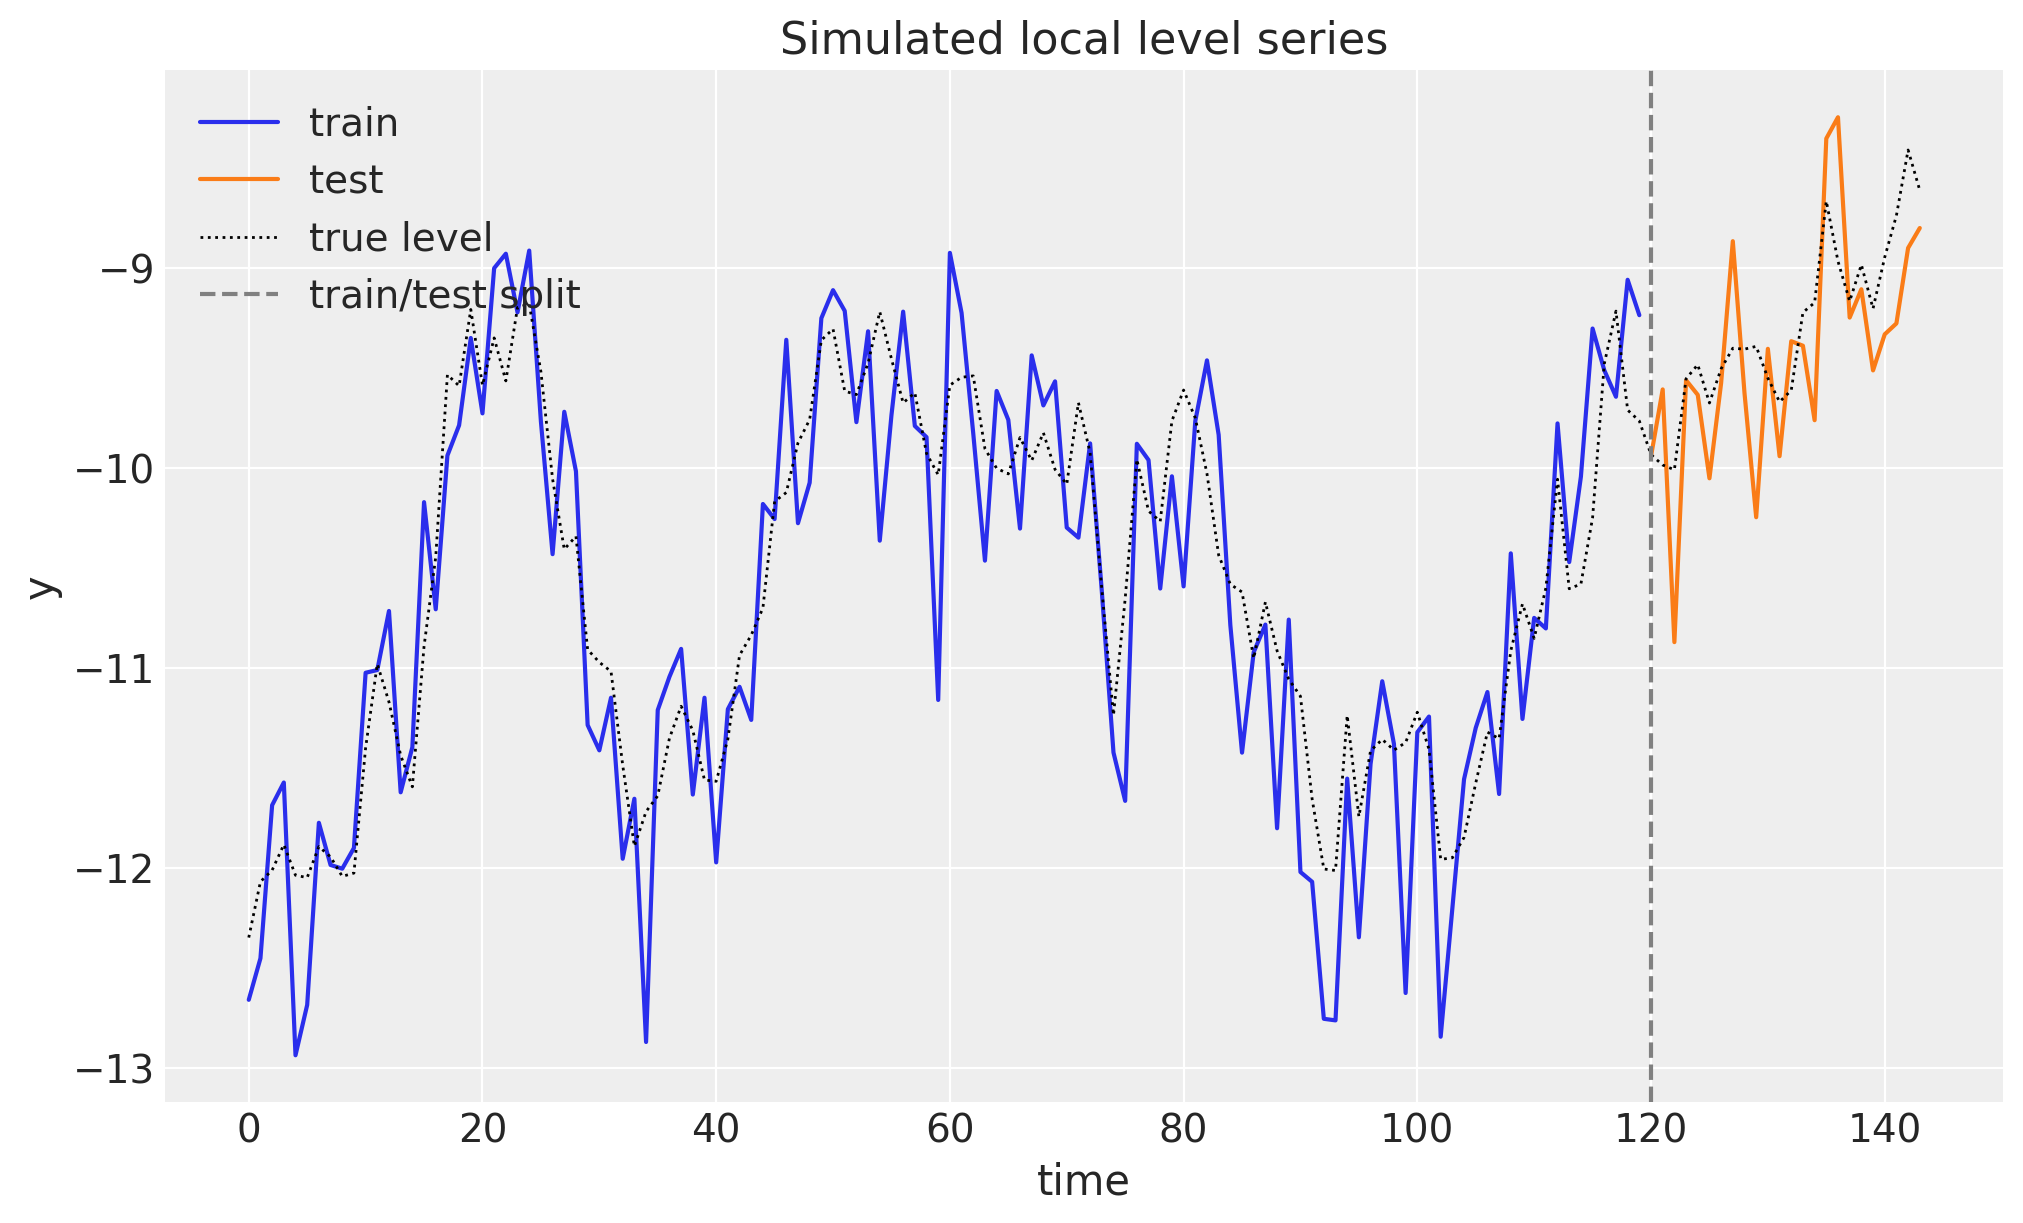

In [3]:
q_true, r_true = 0.3, 0.5
t_obs, future = 120, 24
duration = t_obs + future
time_index = np.arange(duration)
time_grid = np.arange(duration, dtype=np.float32)  # the step index, the time grid of the block

rng_key, rng_subkey = random.split(rng_key)
simulated = dsx.simulate(
    local_level_dynamics(jnp.asarray(q_true), jnp.asarray(r_true)),
    rng_key=rng_subkey,
    predict_times=jnp.asarray(time_grid),
)
assert simulated.observations is not None and simulated.states is not None  # raw simulation
y_full = simulated.observations[0]  # (duration, 1)
x_true = simulated.states[0, :, 0]  # (duration,)

train_data, test_data = y_full[:t_obs], y_full[t_obs:]
covariates_full = y_full  # the series doubles as the covariate
covariates_train = covariates_full[:t_obs]

fig, ax = plt.subplots()
ax.plot(time_index[:t_obs], train_data[:, 0], color="C0", label="train")
ax.plot(time_index[t_obs:], test_data[:, 0], color="C1", label="test")
ax.plot(time_index, x_true, color="black", lw=1, ls=":", label="true level")
ax.axvline(t_obs, color="gray", linestyle="--", label="train/test split")
ax.legend(loc="upper left")
ax.set(title="Simulated local level series", xlabel="time", ylabel="y");

The level moves as a random walk, and the observations scatter around it with the larger noise scale $r$.

### Prior Predictive Checks

The priors on both scales are $\text{HalfNormal}(1)$, and the initial level is $\text{Normal}(0, 10)$. Before fitting anything, we look at the series these priors generate.

For a state space model the prior predictive is a forward simulation. We write a small generative model in native `dynestyx` style (`dsx.sample` with `predict_times` only) and run it under a `Simulator` with NumPyro's `Predictive`.

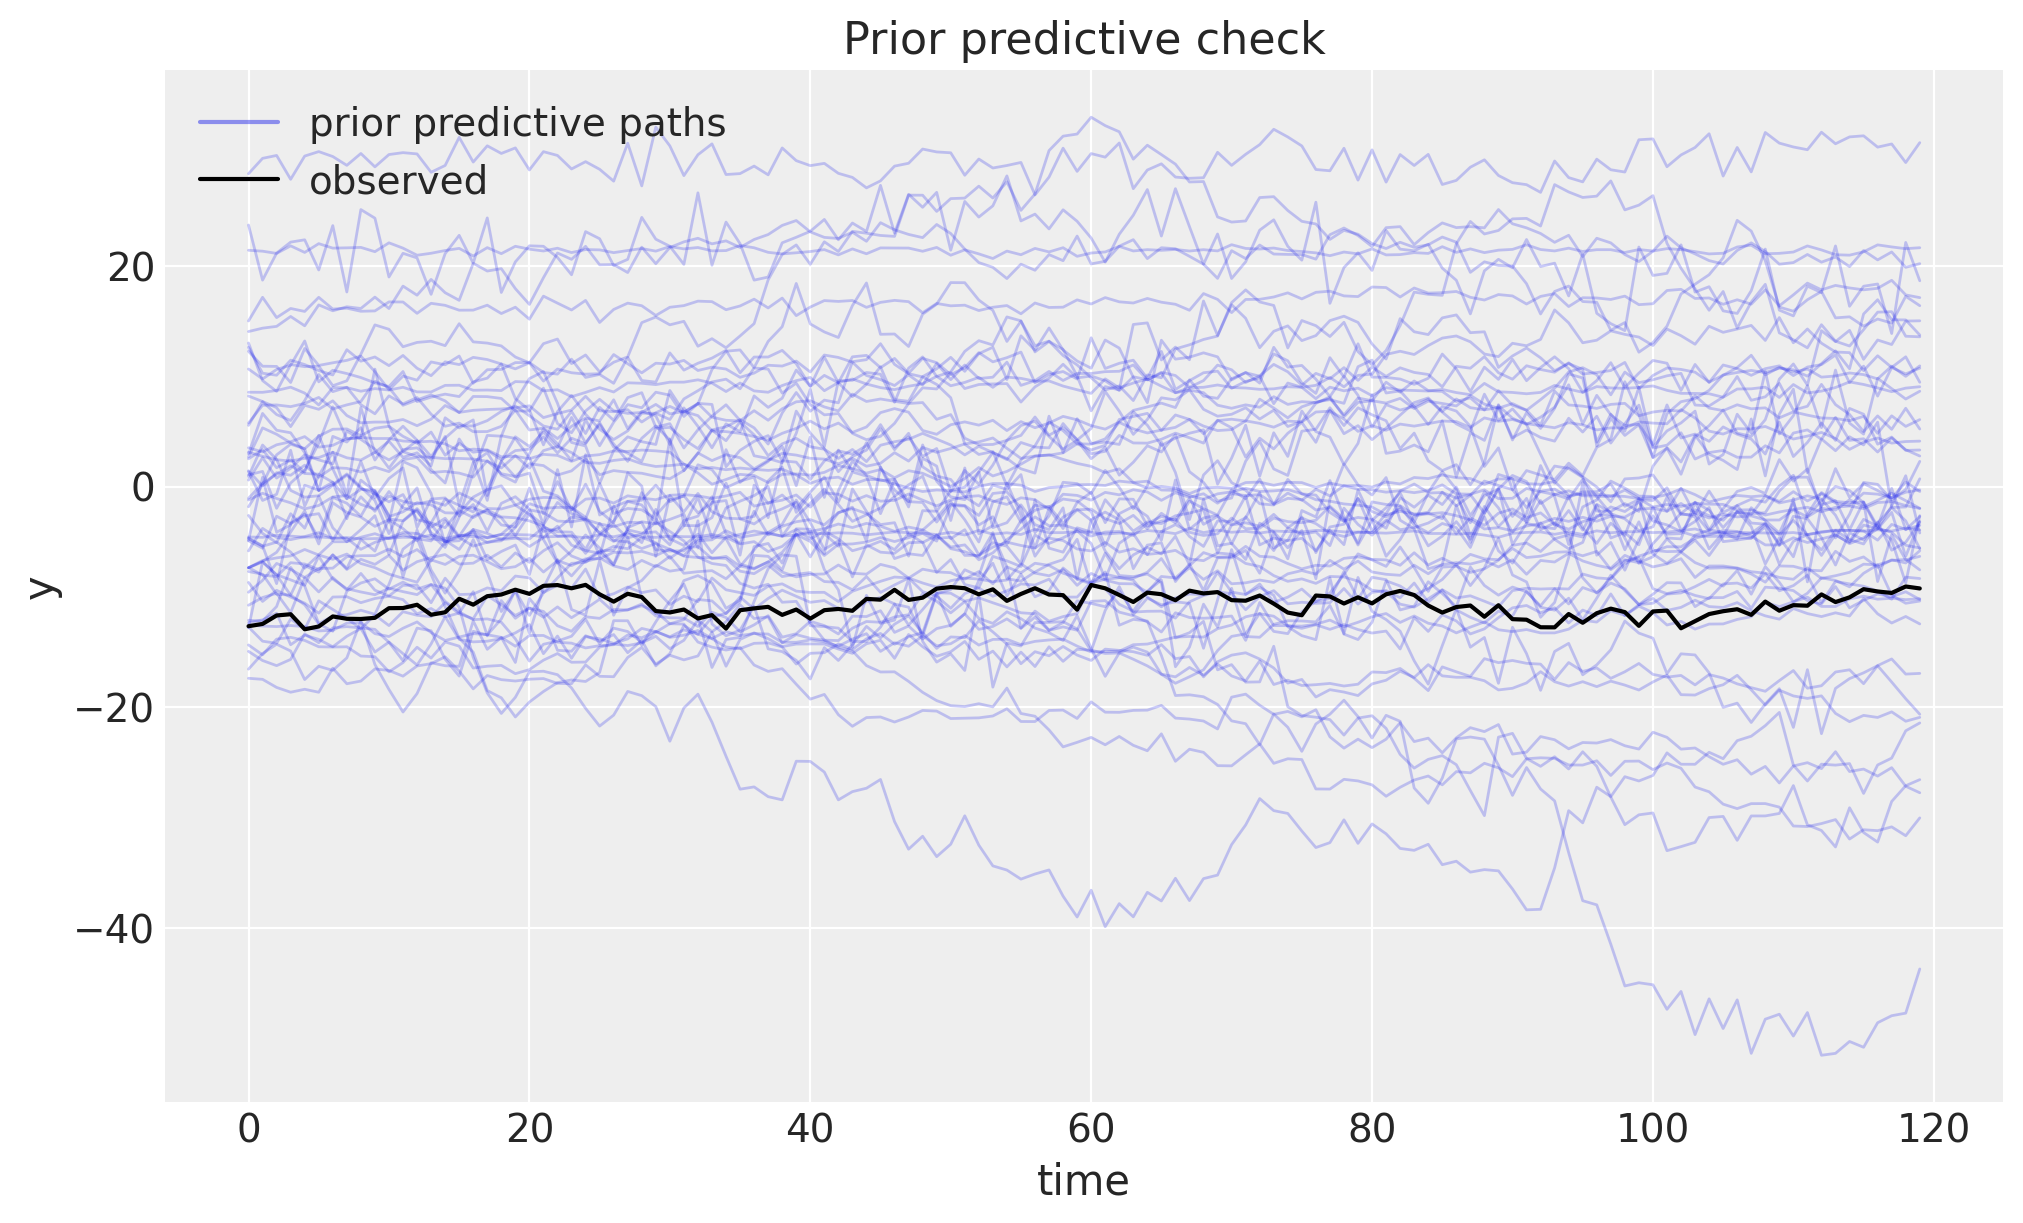

In [4]:
def local_level_prior(predict_times: Array) -> None:
    """Sample the scales from their priors and simulate a path from the local level model."""
    q = numpyro.sample("q", dist.HalfNormal(1.0))
    r = numpyro.sample("r", dist.HalfNormal(1.0))
    dsx.sample("f", local_level_dynamics(q, r), predict_times=predict_times)


rng_key, rng_subkey = random.split(rng_key)
with Simulator(n_simulations=1):
    prior_draws = Predictive(local_level_prior, num_samples=50)(
        rng_subkey, predict_times=jnp.asarray(time_grid[:t_obs])
    )
prior_paths = np.asarray(prior_draws["f_observations"][:, 0, :, 0])  # (50, t_obs)

fig, ax = plt.subplots()
ax.plot(time_index[:t_obs], prior_paths.T, color="C0", alpha=0.25, lw=1)
ax.plot([], [], color="C0", alpha=0.5, label="prior predictive paths")
ax.plot(time_index[:t_obs], train_data[:, 0], color="black", lw=1.5, label="observed")
ax.legend(loc="upper left")
ax.set(title="Prior predictive check", xlabel="time", ylabel="y");

The prior paths cover the observed series without being too wide, which is good.

### Model Specification

All models are plain NumPyro functions `(covariates, data=None)` with the same priors. They differ only in how the latent level enters the trace.

The **direct** model is the idiomatic `numpyro_forecast` form. [`innovations`](../../reference/models.innovations.html) samples one innovation per time step (with a `LocScaleReparam` to soften the funnel between $q$ and the path), the level is their cumulative sum plus the initial level `x0`, and [`predict`](../../reference/models.predict.html) registers the likelihood. The sampler explores $t_{\text{obs}} + 3$ dimensions. One small difference with the `dynestyx` model: here the first observation sees `x0` plus one innovation, while `dynestyx` observes its initial state directly. With a $\text{Normal}(0, 10)$ prior on the initial level this difference has no visible effect on the posteriors.

The two **`dynestyx`** fits share one model function, `local_level_ssm`, and differ in the handler around the fit. With a `LatentPathBuilder` the path is explicit: one sample site of shape $(t_{\text{obs}}, 1)$ plus the two scales. With a `Smoother` the Kalman smoother integrates the path out exactly, and the sampler explores $2$ dimensions.

We use `KFSmootherConfig(filter_source="cd_dynamax")`, the exact Rauch-Tung-Striebel smoother on the backend that was cheapest per gradient in our measurements for a short series on the CPU. The `filter_source="cuthbert"` backend adds support for missing observations and time-varying parameters at a higher cost per gradient. We also create a `Filter` with the matching `KFConfig()`, for the cost measurement and the filtering view of the level below.

Every model registers a `level` deterministic site when it is called without data. The direct model computes its level in place, and the `dynestyx` models take it from the `x_in_sample` field of the block's result, which is the in-window state draw behind the in-sample predictive. We read that site later to compare the three reconstructions of the level.

In [5]:
def local_level_direct(covariates: Array, data: Array | None = None) -> None:
    """Local level model with the innovations sampled explicitly."""
    h = Horizon.from_data(covariates, data)
    q = numpyro.sample("q", dist.HalfNormal(1.0))
    r = numpyro.sample("r", dist.HalfNormal(1.0))
    x0 = numpyro.sample("x0", dist.Normal(0.0, 10.0))
    drift = innovations(h, "drift", dist.Normal(0.0, q), reparam=LocScaleReparam(0))
    level = x0 + jnp.cumsum(drift, axis=-2)
    if h.data is None:
        numpyro.deterministic("level", level)
    predict(h, dist.Normal(0.0, r), level)


def local_level_ssm(covariates: Array, data: Array | None = None) -> None:
    """Local level model as a dynestyx state space model; the handler around the call decides."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :]  # the observed window travels in the covariates
    q = numpyro.sample("q", dist.HalfNormal(1.0))
    r = numpyro.sample("r", dist.HalfNormal(1.0))
    result = state_space(h, "f", y, local_level_dynamics(q, r))
    if result.x_in_sample is not None:  # set when the model is called without data
        numpyro.deterministic("level", result.x_in_sample)


latent_path = LatentPathBuilder()
smoother = Smoother(smoother_config=KFSmootherConfig(filter_source="cd_dynamax"))
kalman_filter = Filter(filter_config=KFConfig())

### Model Fitting

We run the same sampler budget on the three models: $4$ chains of $1{,}000$ warmup and $1{,}000$ sampling steps. The `num_steps` extra field records the number of leapfrog steps of the sampling phase, one gradient evaluation each, which is where NUTS spends its time. Warmup steps and the compilation are not counted, but they are part of the wall time.

Each strategy is a model and the handler around its calls. The direct model needs no handler, so `nullcontext()` stands in for it. We keep the `LatentPathBuilder` instance of the fit for every later call of that model.

`mcmc.get_samples()` returns the flat posterior dictionary that the package drivers consume. For the `dynestyx` models it also carries the deterministic sites their handlers record (`f_marginal_loglik`, `f_state_path`, ...).

In [6]:
def fit_nuts(
    rng_key: Array,
    model: ForecastModel,
    data: Array,
    covariates: Array,
    *,
    num_chains: int = 4,
    num_warmup: int = 1_000,
    num_samples: int = 1_000,
) -> tuple[MCMC, float]:
    """Fit ``model`` with NUTS and return the sampler and the wall time in seconds."""
    mcmc = MCMC(
        NUTS(model),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=num_chains,
        chain_method="sequential",
        progress_bar=False,
    )
    start = time.perf_counter()
    mcmc.run(rng_key, covariates, data, extra_fields=("num_steps",))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, time.perf_counter() - start


strategies: dict[str, tuple[ForecastModel, AbstractContextManager]] = {
    "direct (innovations)": (local_level_direct, nullcontext()),
    "dynestyx, explicit path": (local_level_ssm, latent_path),
    "dynestyx, Kalman smoother": (local_level_ssm, smoother),
}
fits: dict[str, tuple[MCMC, float]] = {}

for label, (model, handler) in strategies.items():
    rng_key, rng_subkey = random.split(rng_key)
    with handler:
        fits[label] = fit_nuts(rng_subkey, model, train_data, covariates_train)

posteriors = {label: mcmc.get_samples() for label, (mcmc, _) in fits.items()}

### Model Diagnostics

Before looking at the results, we check some diagnostics. The posteriors of the two scales must agree with each other, because the three models describe the same process and the smoother integrates the level out exactly. What differs is the work the sampler has to do.

For every fit we collect the posterior mean and standard deviation, the bulk effective sample size and $\hat{R}$ of the two scales with ArviZ, next to the number of gradient evaluations and the wall time. ArviZ needs the `(chain, draw)` layout, which `get_samples(group_by_chain=True)` returns. The true values are $q = 0.3$ and $r = 0.5$.

In [7]:
def summarize_fit(mcmc: MCMC, seconds: float) -> dict[str, int | float]:
    """Posterior means, diagnostics and sampler cost of ``q`` and ``r`` for one fit."""
    grouped = mcmc.get_samples(group_by_chain=True)
    tree = az.from_dict({"posterior": {name: np.asarray(grouped[name]) for name in ("q", "r")}})
    summary = az.summary(tree, fmt="xarray", round_to="none")
    stats = {"mean": 3, "sd": 3, "ess_bulk": 0, "r_hat": 3}
    return {
        f"{stat} {name}": round(float(summary[name].sel(summary=stat)), digits)
        for name in ("q", "r")
        for stat, digits in stats.items()
    } | {
        "leapfrog steps": int(np.asarray(mcmc.get_extra_fields()["num_steps"]).sum()),
        "wall time (s)": round(seconds, 1),
    }


pl.DataFrame(
    [{"fit": label} | summarize_fit(mcmc, seconds) for label, (mcmc, seconds) in fits.items()]
)

fit,mean q,sd q,ess_bulk q,r_hat q,mean r,sd r,ess_bulk r,r_hat r,leapfrog steps,wall time (s)
str,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64
"""direct (innovations)""",0.386,0.059,669.0,1.006,0.442,0.05,754.0,1.005,1018374,7.4
"""dynestyx, explicit path""",0.387,0.062,674.0,1.009,0.44,0.052,1138.0,1.002,65544,8.1
"""dynestyx, Kalman smoother""",0.387,0.061,1590.0,1.003,0.44,0.051,1694.0,1.004,17992,12.0


The three posterior means agree closely. The $\hat{R}$ values are between $1.002$ and $1.009$, below the usual threshold of $1.01$. With $120$ observations the scales are only moderately well identified, so a posterior mean one to one and a half standard deviations away from the truth is not surprising.

The smoothed model reaches the largest effective sample size with a small fraction of the gradient evaluations. It moves in a $2$-dimensional posterior instead of a $123$-dimensional one, where the likelihood still couples $q$ to every innovation after the non-centered reparameterization.

The explicit path built by `dynestyx` sits between the two. It needs far fewer gradients than the direct model and reaches about the same effective sample size for $q$ ($674$ against $669$), less than half of the smoother's $1{,}590$.

Each smoother gradient costs more than a gradient of the direct model: it runs a Kalman pass over the window instead of a sum of Gaussian log densities. So on a short series on the CPU the smoother fit is not faster: it took $12.0$ seconds against $7.4$ seconds for the direct model, compilation and warmup included. The advantage grows with the length of the series. The dimension of the direct posterior grows with it, while the dimension the smoother's sampler explores stays $2$, and the cost of a Kalman pass is linear in the length. On accelerators the `cuthbert` backend can also use its associative (parallel-in-time) scan, which we do not measure here.

We now measure the two costs that the building block section refers to. The first is a full model evaluation, which returns the marginal log likelihood and the state estimates. The second is the gradient of the log density, which is what NUTS and SVI evaluate; we also measure it for the direct model. Both are compiled with `jax.jit` on the training window and timed at the true scales, after the compilation. The direct model also needs its innovations, which we take from one posterior draw.

In [8]:
def timed(
    fn: Callable[[dict[str, Array]], Any], params: dict[str, Array], num_evals: int
) -> float:
    """Average wall time in milliseconds of ``fn`` at ``params``, after compilation."""
    jax.block_until_ready(fn(params))
    start = time.perf_counter()
    for _ in range(num_evals):
        out = fn(params)
    jax.block_until_ready(out)
    return (time.perf_counter() - start) / num_evals * 1e3


true_scales = {"q": jnp.asarray(q_true), "r": jnp.asarray(r_true)}
direct_mcmc = fits["direct (innovations)"][0]
direct_params = {  # one posterior draw of every sample site, at the true scales
    **{name: posteriors["direct (innovations)"][name][0] for name in direct_mcmc.last_state.z},
    **true_scales,
}


def evaluation_cost(handler: Filter | Smoother, site: str, num_evals: int = 1_000) -> float:
    """Milliseconds per compiled model evaluation, returning the log likelihood and ``site``."""

    def run(params: dict[str, Array]) -> tuple[Array, Array]:
        substituted = numpyro.handlers.substitute(local_level_ssm, data=params)
        tr = numpyro.handlers.trace(substituted).get_trace(covariates_train, train_data)
        return tr["f_marginal_loglik"]["value"], tr[site]["value"]

    with handler:  # the handler must be active when jax.jit traces the model
        return timed(jax.jit(run), true_scales, num_evals)


def gradient_cost(
    model: ForecastModel,
    handler: AbstractContextManager,
    params: dict[str, Array],
    num_evals: int = 1_000,
) -> float:
    """Milliseconds per compiled ``value_and_grad`` of the log density of ``model``."""

    def log_joint(params: dict[str, Array]) -> Array:
        return log_density(model, (covariates_train, train_data), {}, params)[0]

    with handler:
        return timed(jax.jit(jax.value_and_grad(log_joint)), params, num_evals)


evaluation_ms = {
    "Filter": evaluation_cost(kalman_filter, "f_filtered_states_mean"),
    "Smoother": evaluation_cost(smoother, "f_smoothed_states_mean"),
}
gradient_ms = {
    "Filter": gradient_cost(local_level_ssm, kalman_filter, true_scales),
    "Smoother": gradient_cost(local_level_ssm, smoother, true_scales),
    "direct (innovations)": gradient_cost(local_level_direct, nullcontext(), direct_params),
}
pl.DataFrame(
    {
        "model": list(gradient_ms),
        "evaluation (ms)": [evaluation_ms.get(label) for label in gradient_ms],
        "gradient (ms)": list(gradient_ms.values()),
    }
).with_columns(pl.col(pl.Float64).round(3))

model,evaluation (ms),gradient (ms)
str,f64,f64
"""Filter""",0.051,0.16
"""Smoother""",0.08,0.162
"""direct (innovations)""",null,0.01


A full evaluation costs more under the `Smoother` because of its backward pass. The gradient costs the same under both handlers, because the marginal log likelihood depends on the forward pass only and JAX drops the unused backward pass from the compiled gradient. A gradient of the direct model costs much less than either. The smoother needs far fewer gradients, but each one costs more, which is why its fit is not faster than the direct fit on this short series.

Next, we overlay the three posteriors of the two scales.

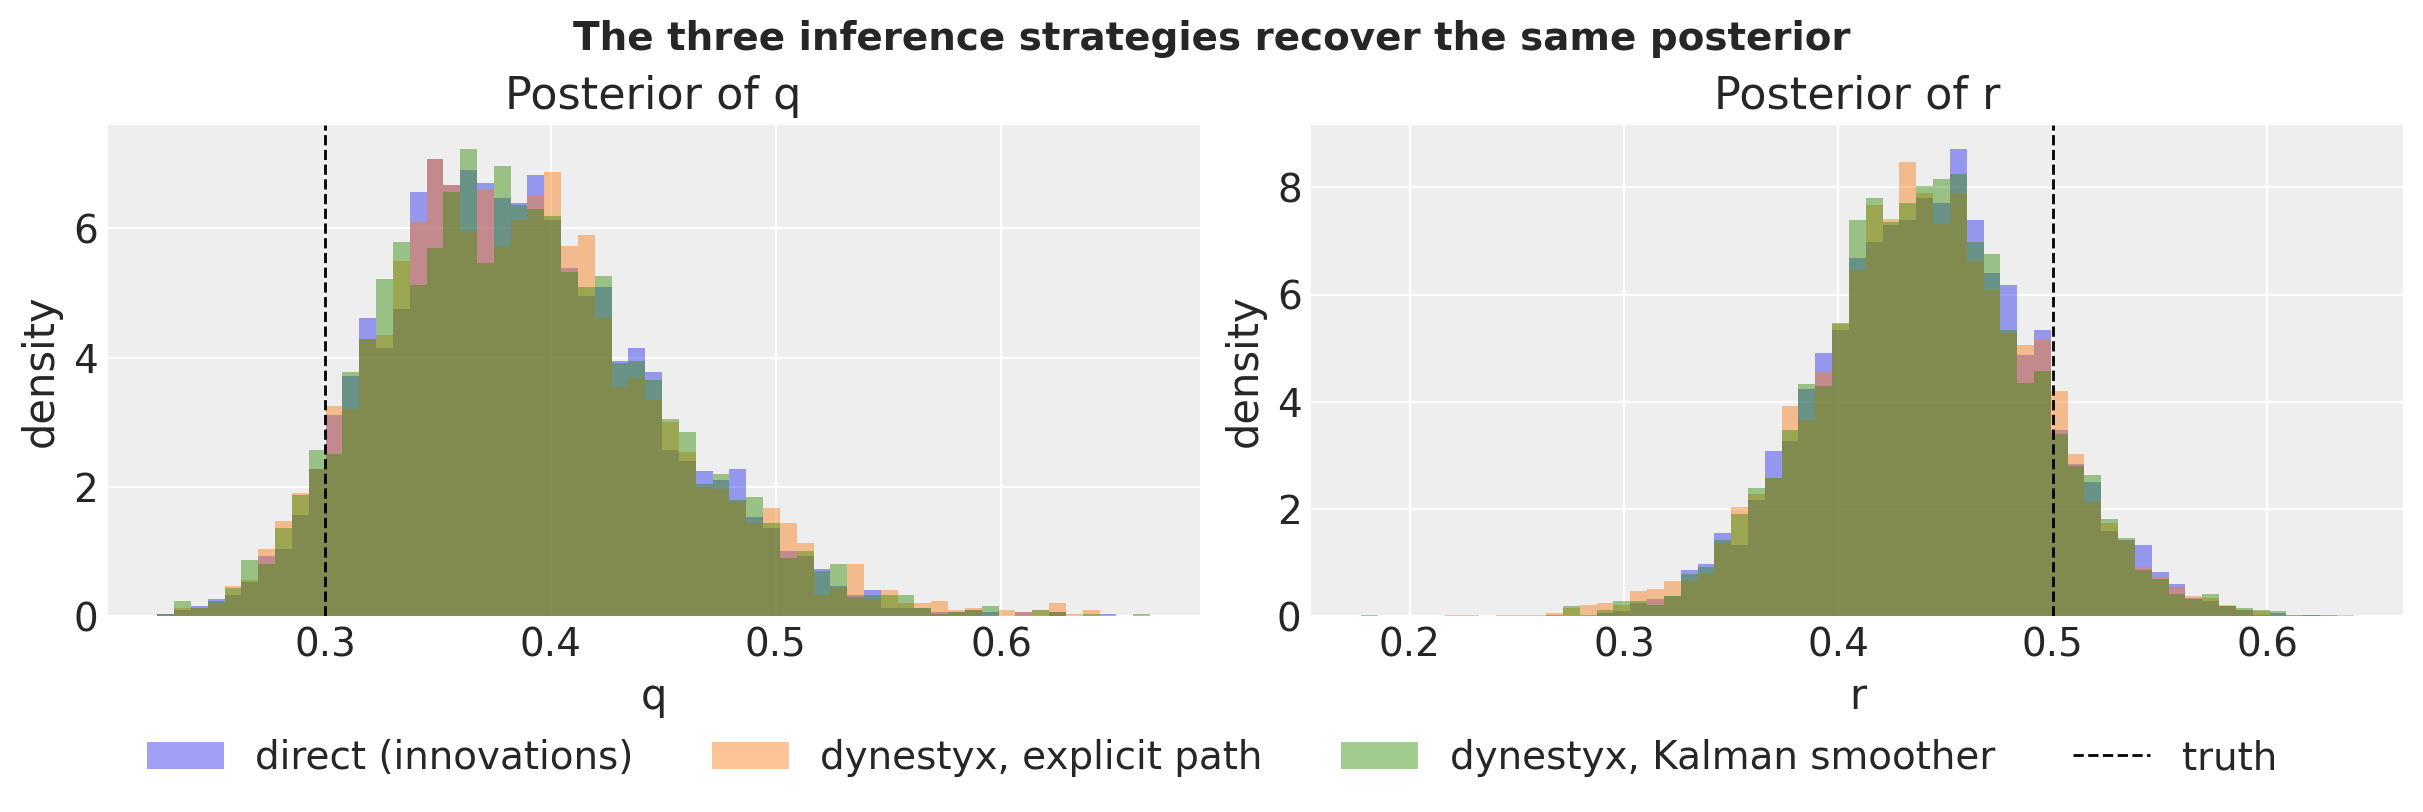

In [9]:
colors = {label: f"C{i}" for i, label in enumerate(strategies)}
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), layout="constrained")
for ax, name, truth in zip(axes, ("q", "r"), (q_true, r_true), strict=True):
    values = {label: np.asarray(post[name]) for label, post in posteriors.items()}
    bins = np.linspace(
        min(v.min() for v in values.values()), max(v.max() for v in values.values()), 60
    )
    for label, v in values.items():
        ax.hist(v, bins=bins, density=True, alpha=0.45, color=colors[label], label=label)
    ax.axvline(truth, color="black", ls="--", lw=1, label="truth")
    ax.set(title=f"Posterior of {name}", xlabel=name, ylabel="density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=4)
fig.suptitle(
    "The three inference strategies recover the same posterior", fontsize=14, fontweight="bold"
);

The three histograms lie on top of each other. The truth falls in the left tail of the posterior of $q$ and in the right tail of the posterior of $r$, as the means and standard deviations of the table above show.

### Forecast

Forecasting uses the package's [`forecast`](../../reference/predictive.forecast.html) driver in all three cases. It runs `Predictive` over the full-horizon covariates and returns the `"forecast"` site with one path per posterior draw.

For the direct model the in-sample innovations are replayed from the posterior and the future ones are drawn from the prior. For the `dynestyx` models every draw conditions again on the training window with its own $(q, r)$: the smoother recomputes the smoothing distribution and the builder reconstructs the posterior path. The simulator then rolls the conditioned state forward.

This re-conditioning is one vectorized pass over the window per draw, which is cheap here. For a long history that many forecasts share, [`end_state`](../../reference/contrib.dynestyx.end_state.html) and [`start_state`](../../reference/contrib.dynestyx.start_state.html) let the forecasts resume from the filtered state of one filter pass, as the section *Reusing a Filtered History* of the [getting started example](dynestyx_getting_started.html) shows.

For the `dynestyx` models a `DiscreteTimeSimulator` goes around the call, outside the handler of the fit. The driver compiles once per call, so the handlers that are active at the call apply to it, and they run under the `jit` and `vmap` of the driver without special treatment.

In [10]:
forecasts: dict[str, Array | np.ndarray] = {}

for label, (model, handler) in strategies.items():
    rng_key, rng_subkey = random.split(rng_key)
    with DiscreteTimeSimulator(n_simulations=1), handler:
        forecasts[label] = forecast(
            rng_subkey, model, posteriors[label], train_data, covariates_full
        )

We plot the three forecasts one above the other, with their $50\%$ and $94\%$ HDI bands and the test CRPS of each in the panel title.

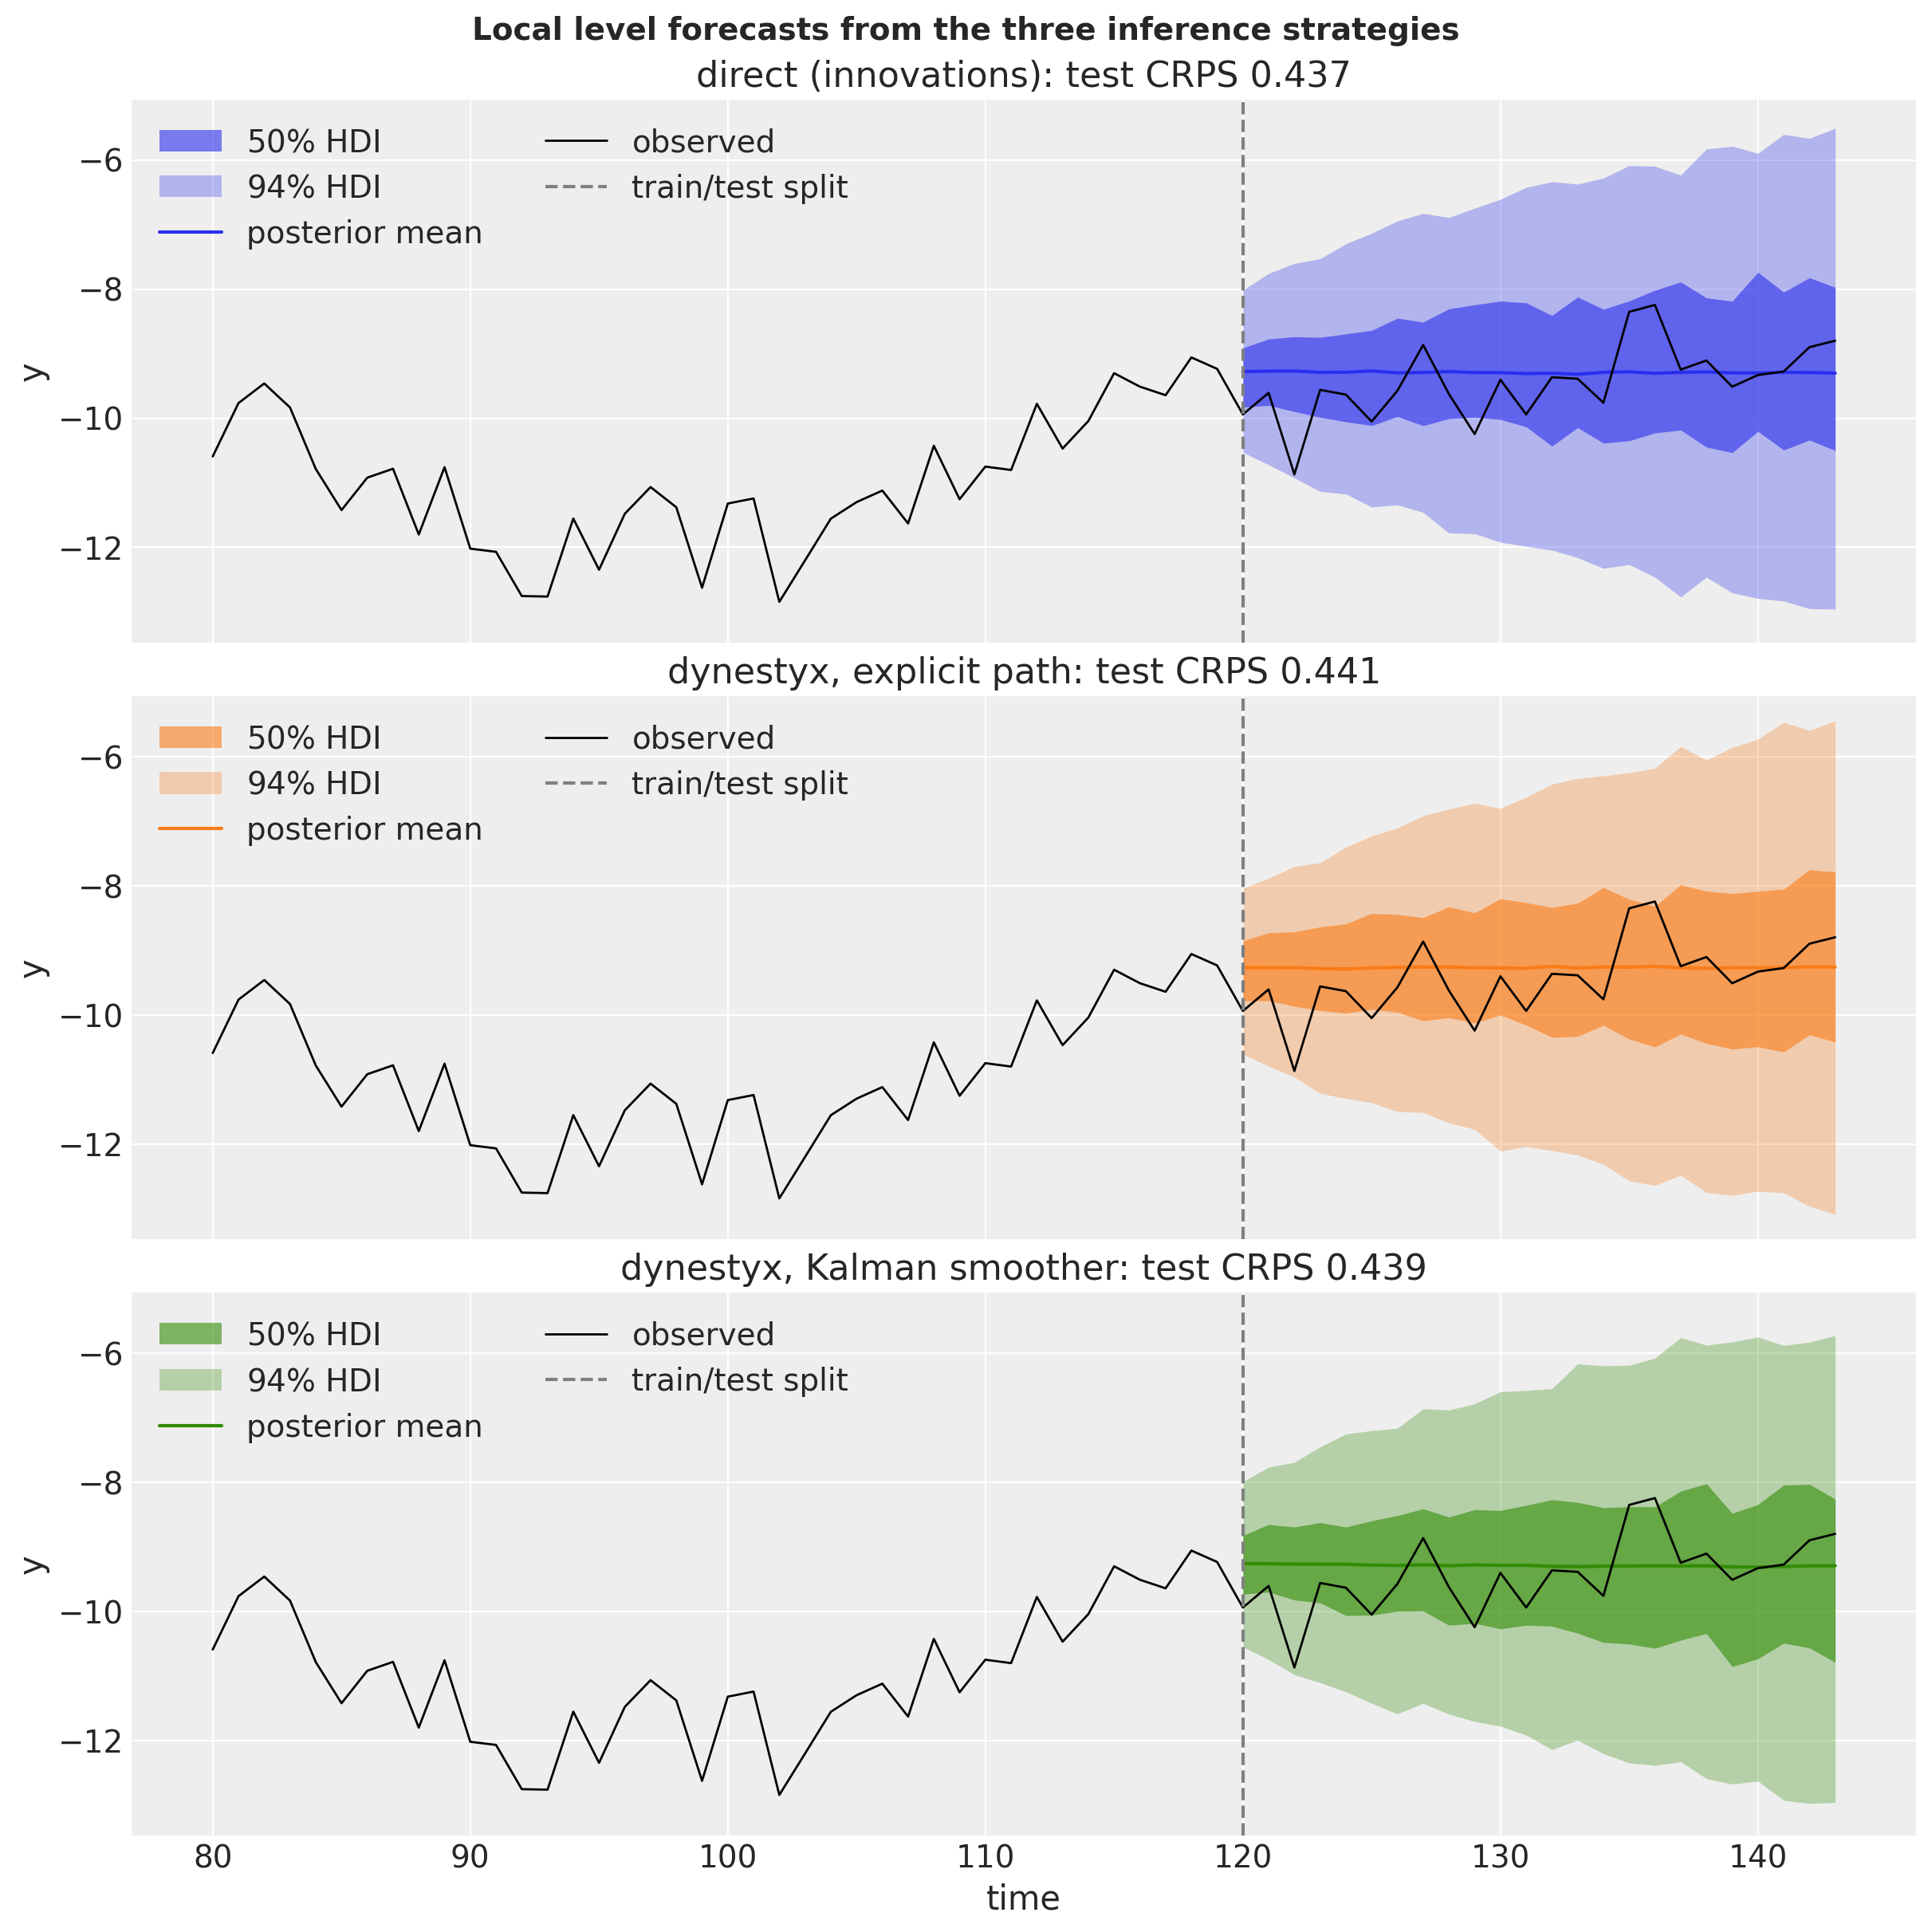

In [11]:
def hdi_label(prob: float, prefix: str = "") -> str:
    r"""Legend label for an HDI band, e.g. ``$94\%$ HDI``."""
    percent = f"{prob:.0%}".replace("%", r"\%")
    return f"{prefix}${percent}$ HDI"


hdi_probs = (0.5, 0.94)
hdi_alphas = [0.6, 0.3]  # 50% band darker, 94% band lighter
future_index = time_index[t_obs:]

pc = az.plot_lm(
    predictions_to_datatree(
        np.concatenate([np.asarray(draws) for draws in forecasts.values()], axis=-1),
        future_index,
        list(forecasts),
    ),
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    point_estimate="mean",
    col_wrap=1,
    aes={"color": ["series"], "alpha": ["prob"]},
    alpha=hdi_alphas,
    aes_by_visuals={"pe_line": ["color"]},
    visuals={
        "observed_scatter": False,
        "pe_line": {"alpha": 1.0, "width": 1.5},
        "xlabel": False,
        "ylabel": False,
    },
    figure_kwargs={"figsize": (12, 12), "sharex": True, "sharey": True},
)
for label, draws in forecasts.items():
    ax = pc.get_target("t", {"series": label})
    ax.plot(
        time_index[t_obs - 40 :], y_full[t_obs - 40 :, 0], color="black", lw=1, label="observed"
    )
    ax.axvline(t_obs, color="gray", linestyle="--", label="train/test split")
    for prob in hdi_probs:
        pc.viz["ci_band"]["t"].sel(series=label, prob=prob).item().set_label(hdi_label(prob))
    pc.viz["pe_line"]["t"].sel(series=label).item().set_label("posterior mean")
    ax.legend(loc="upper left", ncol=2)
    ax.set(title=f"{label}: test CRPS {eval_crps(draws, test_data):.3f}", ylabel="y")
ax.set(xlabel="time")
pc.viz["figure"].item().suptitle(
    "Local level forecasts from the three inference strategies", fontsize=14, fontweight="bold"
);

The three fans are the same forecast up to Monte Carlo error. The `dynestyx` models are the same model as the direct one, up to the initial-state convention of the model specification, with a different parameterization for the sampler.

The same comparison in tabular form: point accuracy through MAE and RMSE, the CRPS as a proper score for the whole predictive distribution, and the empirical coverage of the central $50\%$ and $94\%$ intervals.

In [12]:
metric_fns = {
    "MAE": eval_mae,
    "RMSE": eval_rmse,
    "CRPS": eval_crps,
    "coverage (50%)": partial(eval_coverage, alpha=0.5),
    "coverage (94%)": partial(eval_coverage, alpha=0.94),
}
pl.DataFrame(
    [
        {"strategy": label}
        | {name: float(fn(draws, test_data)) for name, fn in metric_fns.items()}
        for label, draws in forecasts.items()
    ]
).with_columns(pl.col(pl.Float64).round(3))

strategy,MAE,RMSE,CRPS,coverage (50%),coverage (94%)
str,f64,f64,f64,f64,f64
"""direct (innovations)""",0.445,0.589,0.437,0.833,1.0
"""dynestyx, explicit path""",0.451,0.587,0.441,0.833,1.0
"""dynestyx, Kalman smoother""",0.448,0.591,0.439,0.833,1.0


The metrics on the held-out window agree as well, which is the point of this table. The table does not test calibration. All three strategies put $20$ of the $24$ test points ($0.833$) inside the central $50\%$ interval and every point inside the $94\%$ interval. The $24$ forecast errors share the level error at the split and the random walk after it, so they are strongly correlated. One window of $24$ correlated points is too small to check the coverage of the intervals.

### Posterior Predictive Checks

We now look at the in-sample posterior predictive. Because the observed window travels in the covariates, the package's [`to_datatree`](../../reference/convert.to_datatree.html) applies to the `dynestyx` models as it does to any other. It restores the `(chain, draw)` structure, samples the in-sample posterior predictive by calling the model without data, and, because we pass the full-horizon covariates, writes the forecast into the `predictions` group.

Recall that `data=None` selects the in-sample mode. The window still reaches the model through the covariates, so the in-sample predictive is the smoothing predictive $p(y_t^{\text{rep}} \mid y_{1:T}, \theta)$ and not a prior predictive.

The three models produce it in three ways. The direct model replays its sampled path and adds observation noise. Under the `LatentPathBuilder` the block takes the posterior path that `dynestyx` reconstructs and adds the same noise. Under the `Smoother` the block draws every in-window state from the smoothing distribution $p(x_t \mid y_{1:T}, \theta)$ and adds the noise. The first two are joint draws of the whole path, the third is a set of per-step marginal draws. At every single step the three are the same distribution, which is all the bands below show.

In [13]:
trees: dict[str, xr.DataTree] = {}

for label, (model, handler) in strategies.items():
    rng_key, rng_subkey = random.split(rng_key)
    with DiscreteTimeSimulator(n_simulations=1), handler:
        trees[label] = to_datatree(
            rng_subkey, model, posteriors[label], train_data, covariates_full, num_chains=4
        )

trees["dynestyx, Kalman smoother"]

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:                           (chain: 4, draw: 1000,
│                                              f_smoothed_states_cov_dim_0: 120,
│                                              f_smoothed_states_cov_dim_1: 1,
│                                              f_smoothed_states_cov_dim_2: 1,
│                                              f_smoothed_states_cov_diag_dim_0: 120,
│                                              f_smoothed_states_cov_diag_dim_1: 1,
│                                              f_smoothed_states_mean_dim_0: 120,
│                                              f_smoothed_states_mean_dim_1: 1)
│       Coordinates:
│         * chain                             (chain) int64 32B 0 1 2 3
│         * draw                              (draw) int64 8kB 0 1 2 3 ... 997 998 999
│         * f_smoothed_states_cov_dim_0       (f_smoothed_states_cov_dim_0) int64 960B ...
│         * f_smoothed_states_cov_dim_1       (f_smoothed_states_cov_dim_1) int64 8B 0
│         * f_smoothed_states_cov_dim_2       (f_smoothed_states_cov_dim_2) int64 8B 0
│         * f_smoothed_states_cov_diag_dim_0  (f_smoothed_states_cov_diag_dim_0) int64 960B ...
│         * f_smoothed_states_cov_diag_dim_1  (f_smoothed_states_cov_diag_dim_1) int64 8B ...
│         * f_smoothed_states_mean_dim_0      (f_smoothed_states_mean_dim_0) int64 960B ...
│         * f_smoothed_states_mean_dim_1      (f_smoothed_states_mean_dim_1) int64 8B 0
│       Data variables:
│           f_marginal_loglik                 (chain, draw) float32 16kB -124.9 ... -...
│           f_smoothed_states_cov             (chain, draw, f_smoothed_states_cov_dim_0, f_smoothed_states_cov_dim_1, f_smoothed_states_cov_dim_2) float32 2MB ...
│           f_smoothed_states_cov_diag        (chain, draw, f_smoothed_states_cov_diag_dim_0, f_smoothed_states_cov_diag_dim_1) float32 2MB ...
│           f_smoothed_states_mean            (chain, draw, f_smoothed_states_mean_dim_0, f_smoothed_states_mean_dim_1) float32 2MB ...
│           q                                 (chain, draw) float32 16kB 0.3207 ... 0...
│           r                                 (chain, draw) float32 16kB 0.4482 ... 0...
│       Attributes:
│           created_at:                 2026-11-25T22:07:52.970018+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 120, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 960B 0 1 2 3 4 5 6 7 ... 113 114 115 116 117 118 119
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) float32 2MB -12.31 -12.32 ... -9.626
│       Attributes:
│           created_at:                 2026-11-25T22:07:53.538659+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 120, obs_dim: 1)
│       Coordinates:
│         * time     (time) int64 960B 0 1 2 3 4 5 6 7 ... 113 114 115 116 117 118 119
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (time, obs_dim) float32 480B -12.66 -12.45 -11.69 ... -9.059 -9.236
│       Attributes:
│           created_at:                 2026-11-25T22:07:53.538897+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_libra

The tree carries the `posterior`, `posterior_predictive`, `observed_data` and `constant_data` groups and, because the covariates extend past the data, the `predictions` and `predictions_constant_data` groups, as for any other model of the package. To plot the three in-sample bands we merge the `(chain, draw)` dimensions of the `obs` draws into one sample axis.

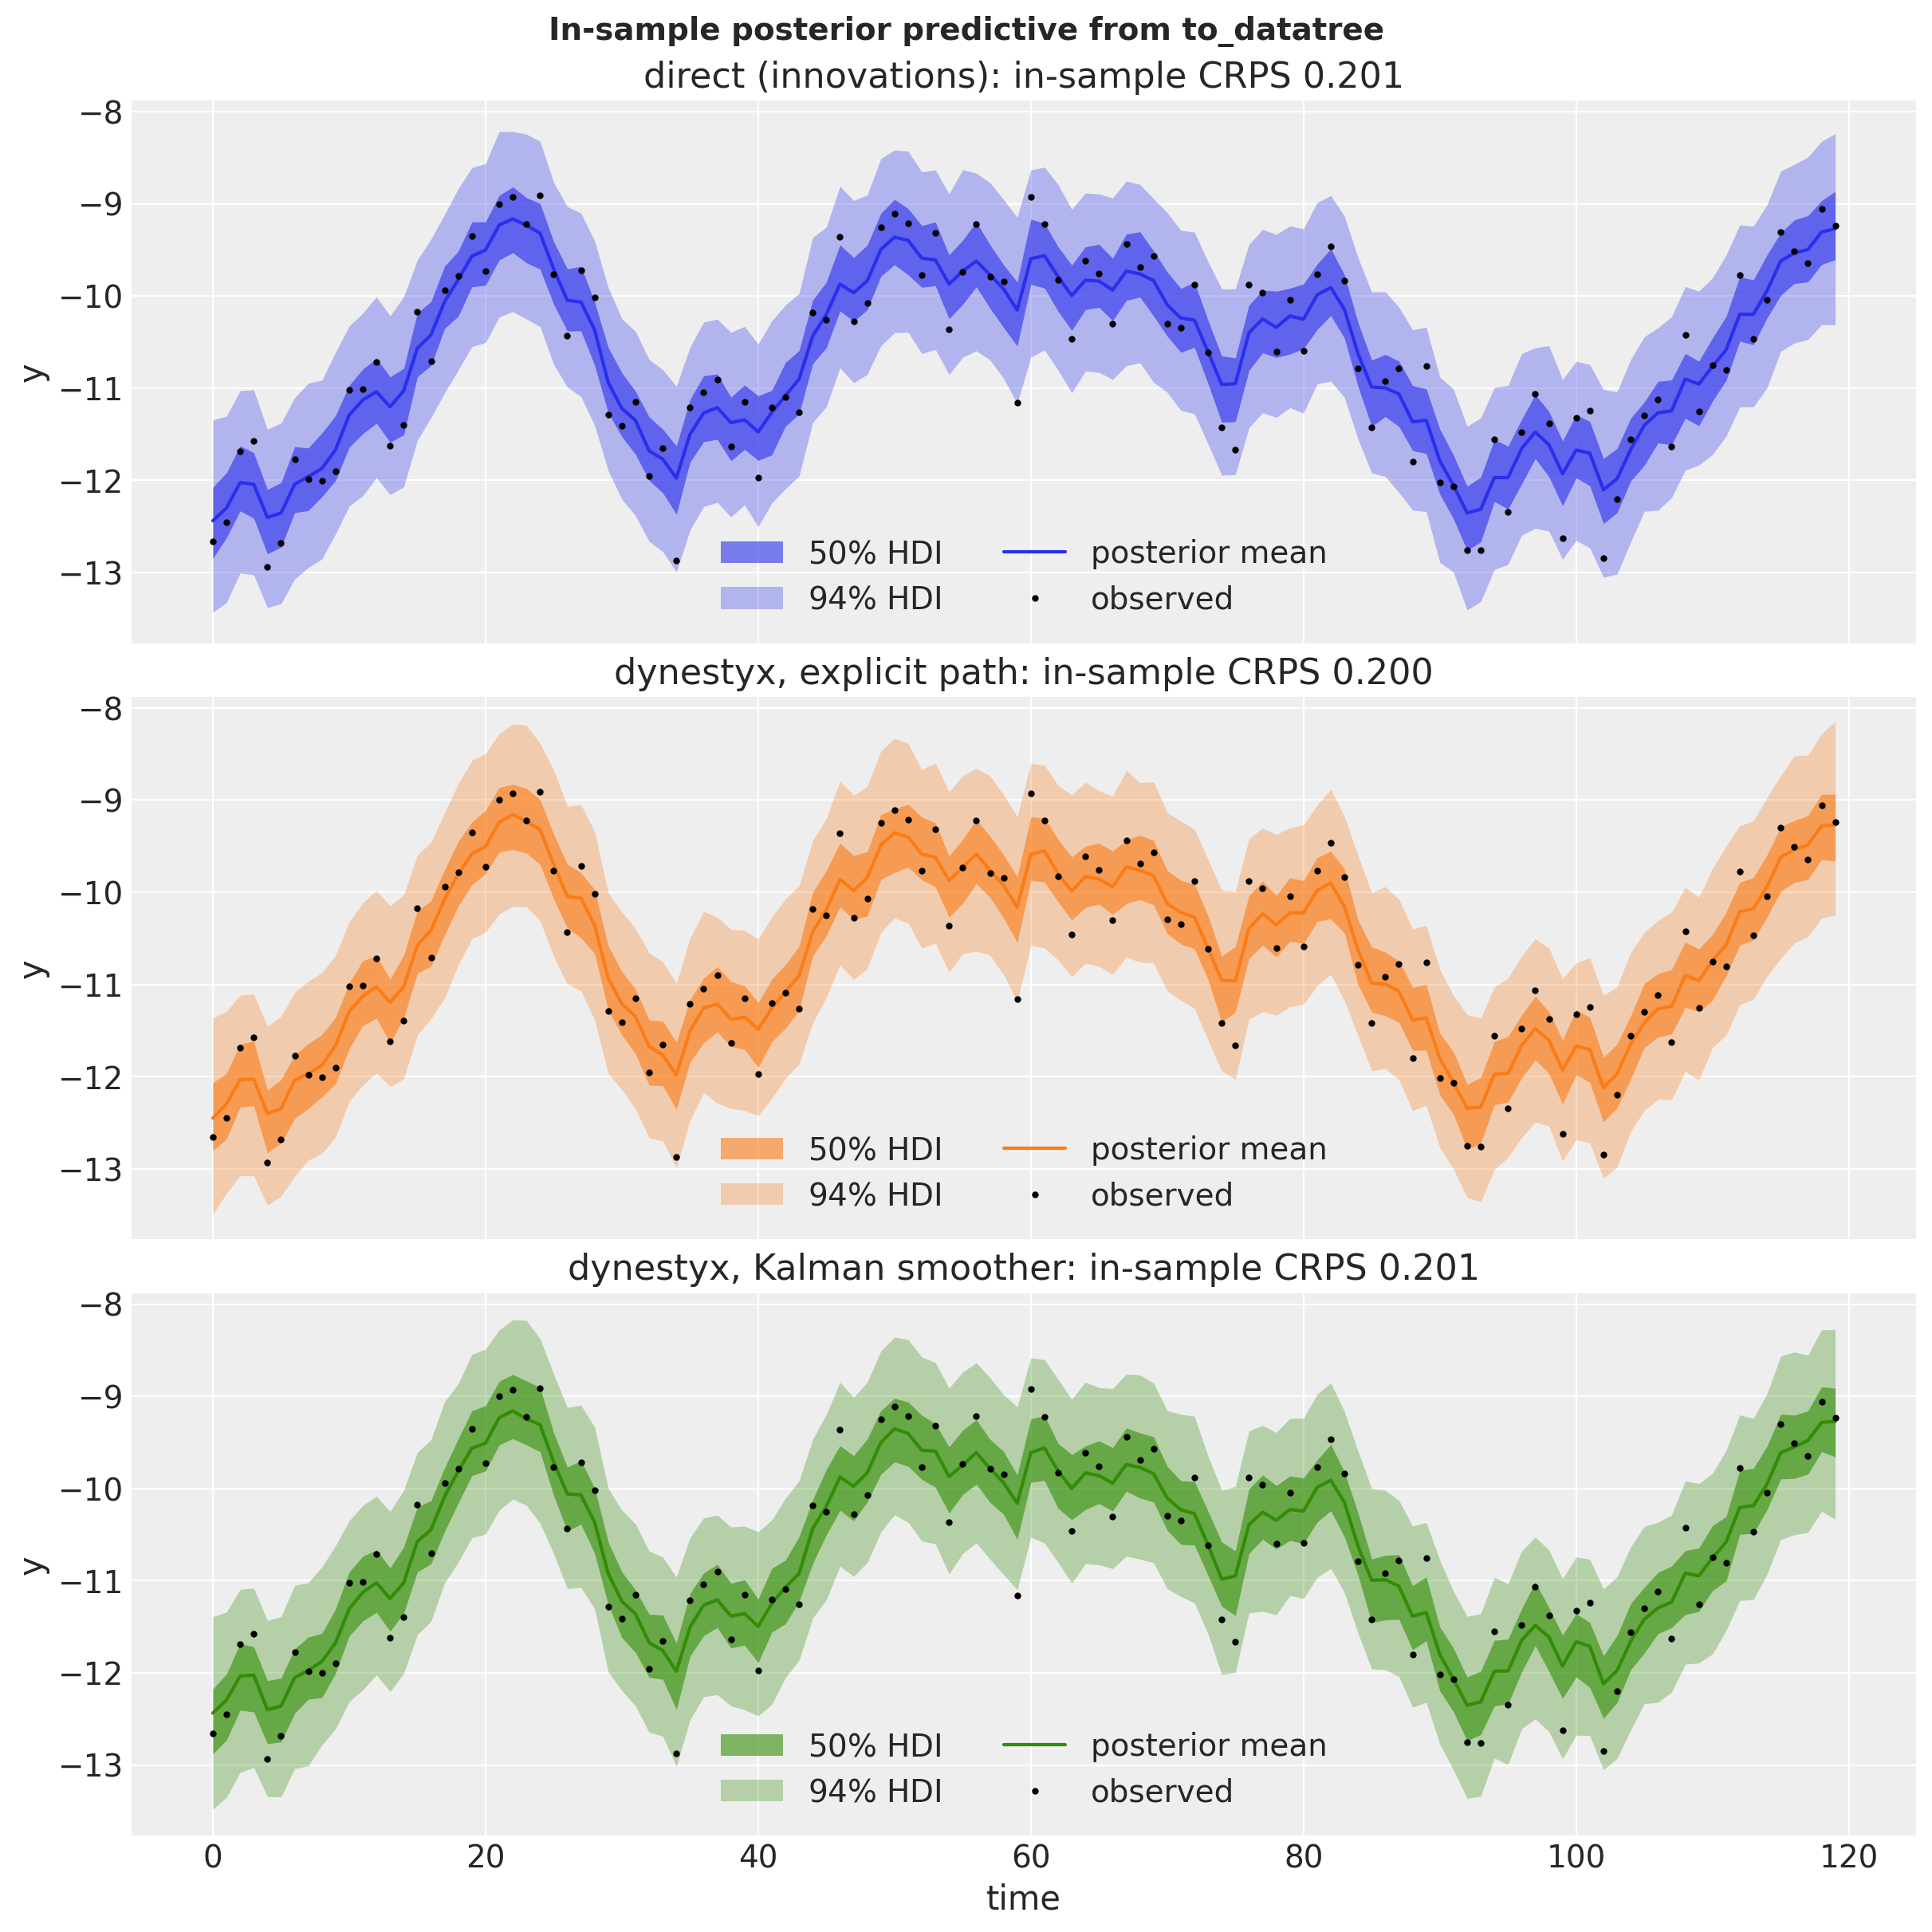

In [14]:
def stacked_draws(tree: xr.DataTree, group: str, var: str) -> np.ndarray:
    """Stack the ``(chain, draw)`` dims of ``tree[group][var]`` into a leading sample axis."""
    return (
        tree[group]
        .dataset[var]
        .stack(sample=("chain", "draw"))
        .transpose("sample", "time", "obs_dim")
        .to_numpy()
    )


in_sample = {
    label: stacked_draws(tree, "posterior_predictive", "obs") for label, tree in trees.items()
}

pc = az.plot_lm(
    predictions_to_datatree(
        np.concatenate(list(in_sample.values()), axis=-1), time_index[:t_obs], list(in_sample)
    ),
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    point_estimate="mean",
    col_wrap=1,
    aes={"color": ["series"], "alpha": ["prob"]},
    alpha=hdi_alphas,
    aes_by_visuals={"pe_line": ["color"]},
    visuals={
        "observed_scatter": False,
        "pe_line": {"alpha": 1.0, "width": 1.5},
        "xlabel": False,
        "ylabel": False,
    },
    figure_kwargs={"figsize": (12, 12), "sharex": True, "sharey": True},
)
for label, draws in in_sample.items():
    ax = pc.get_target("t", {"series": label})
    ax.plot(time_index[:t_obs], train_data[:, 0], ".", color="black", ms=4, label="observed")
    for prob in hdi_probs:
        pc.viz["ci_band"]["t"].sel(series=label, prob=prob).item().set_label(hdi_label(prob))
    pc.viz["pe_line"]["t"].sel(series=label).item().set_label("posterior mean")
    ax.legend(loc="lower center", ncol=2)
    ax.set(title=f"{label}: in-sample CRPS {eval_crps(draws, train_data):.3f}", ylabel="y")
ax.set(xlabel="time")
pc.viz["figure"].item().suptitle(
    "In-sample posterior predictive from to_datatree", fontsize=14, fontweight="bold"
);

The three bands coincide and the in-sample CRPS values agree closely. The `LatentPathBuilder` serves the in-sample predictive as well as the smoother does, so both `dynestyx` strategies work with `predict_in_sample` and `to_datatree`.

### Latent Level Reconstruction

Two claims are easy to mix up here, so we take them one at a time.

**The parameter posterior is the same under a `Filter` and a `Smoother`.** Both handlers put the same number in the trace, the marginal log likelihood $\log p(y_{1:T} \mid \theta)$ of the window, because the Kalman smoother reads it from its forward filtering pass. The posterior $p(\theta \mid y_{1:T})$ is therefore the same under both handlers. We confirm this on the fitted model with `numpyro.infer.util.log_density`, at the posterior mean of the smoothed fit.

In [15]:
smoothed_posterior = posteriors["dynestyx, Kalman smoother"]
posterior_mean = {name: smoothed_posterior[name].mean() for name in ("q", "r")}
log_joint = {}
for name, handler in {"Filter": kalman_filter, "Smoother": smoother}.items():
    with handler:
        log_joint[name] = float(
            log_density(local_level_ssm, (covariates_train, train_data), {}, posterior_mean)[0]
        )
pl.DataFrame(
    {
        "handler": list(log_joint),
        "log joint density at the posterior mean": list(log_joint.values()),
    }
).with_columns(pl.col(pl.Float64).round(6))

handler,log joint density at the posterior mean
str,f64
"""Filter""",-125.142899
"""Smoother""",-125.142899


The two values agree. The draws we already have are draws from the posterior of either model, and we can read them under the other handler without refitting.

**The distributions over the states are different.** The filtering distribution $p(x_t \mid y_{1:t}, \theta)$ conditions on the observations up to step $t$ only. The smoothing distribution $p(x_t \mid y_{1:T}, \theta)$ conditions on the whole window at every step. They answer different questions about the state, and only the second one gives the in-sample predictive of the section above.

Every model registers a `level` site when it is called without data. Calling `Predictive` with the posterior draws and the training covariates only, and asking for that site, gives one level path per posterior draw. The direct model replays `x0` plus the cumulative sum of the sampled `drift`. The builder returns its posterior path and the smoother draws from the smoothing distribution, both through the same `x_in_sample` field of the block's result. All three condition on the whole window, so all three are smoothing reconstructions.

The filtered level needs one more step, because the block has no in-sample mode under a `Filter`. Instead, we record the `f_filtered_states_*` sites with `Predictive` under the `Filter` created above, using the draws of the smoothed fit. Drawing one level per posterior draw from those per-step Gaussians mixes the state uncertainty and the parameter uncertainty into a single band, as the `level` site does for the other three.

In [16]:
levels: dict[str, np.ndarray] = {}

for label, (model, handler) in strategies.items():
    rng_key, rng_subkey = random.split(rng_key)
    level_site = Predictive(model, posterior_samples=posteriors[label], return_sites=["level"])
    with handler:
        levels[label] = np.asarray(level_site(rng_subkey, covariates_train)["level"])

rng_key, key_sites, key_draw = random.split(rng_key, 3)

with kalman_filter:
    filtered_sites = Predictive(
        local_level_ssm,
        posterior_samples=posteriors["dynestyx, Kalman smoother"],
        return_sites=["f_filtered_states_mean", "f_filtered_states_cov_diag"],
    )(key_sites, covariates_train, train_data)
filtered_mean = np.asarray(filtered_sites["f_filtered_states_mean"])
filtered_sd = np.sqrt(np.asarray(filtered_sites["f_filtered_states_cov_diag"]))
filtered_level = filtered_mean + filtered_sd * np.asarray(
    random.normal(key_draw, filtered_mean.shape)
)

The simulation gives us the true level, so we can score the four reconstructions against it. The smoother conditions on more data than the filter, so it should reconstruct the state better, both as a point estimate (RMSE) and as a distribution (CRPS).

In [17]:
true_level = x_true[:t_obs, None]
level_metrics = {"RMSE": eval_rmse, "CRPS": eval_crps}
reconstructions = {"dynestyx, Kalman filter": filtered_level, **levels}
pl.DataFrame(
    [
        {"reconstruction": label}
        | {name: float(fn(draws, true_level)) for name, fn in level_metrics.items()}
        for label, draws in reconstructions.items()
    ]
).with_columns(pl.col(pl.Float64).round(3))

reconstruction,RMSE,CRPS
str,f64,f64
"""dynestyx, Kalman filter""",0.325,0.184
"""direct (innovations)""",0.277,0.156
"""dynestyx, explicit path""",0.279,0.156
"""dynestyx, Kalman smoother""",0.278,0.156


We overlay the filtered and the smoothed level of the same posterior, with their $94\%$ HDI bands and posterior means, on the true level.

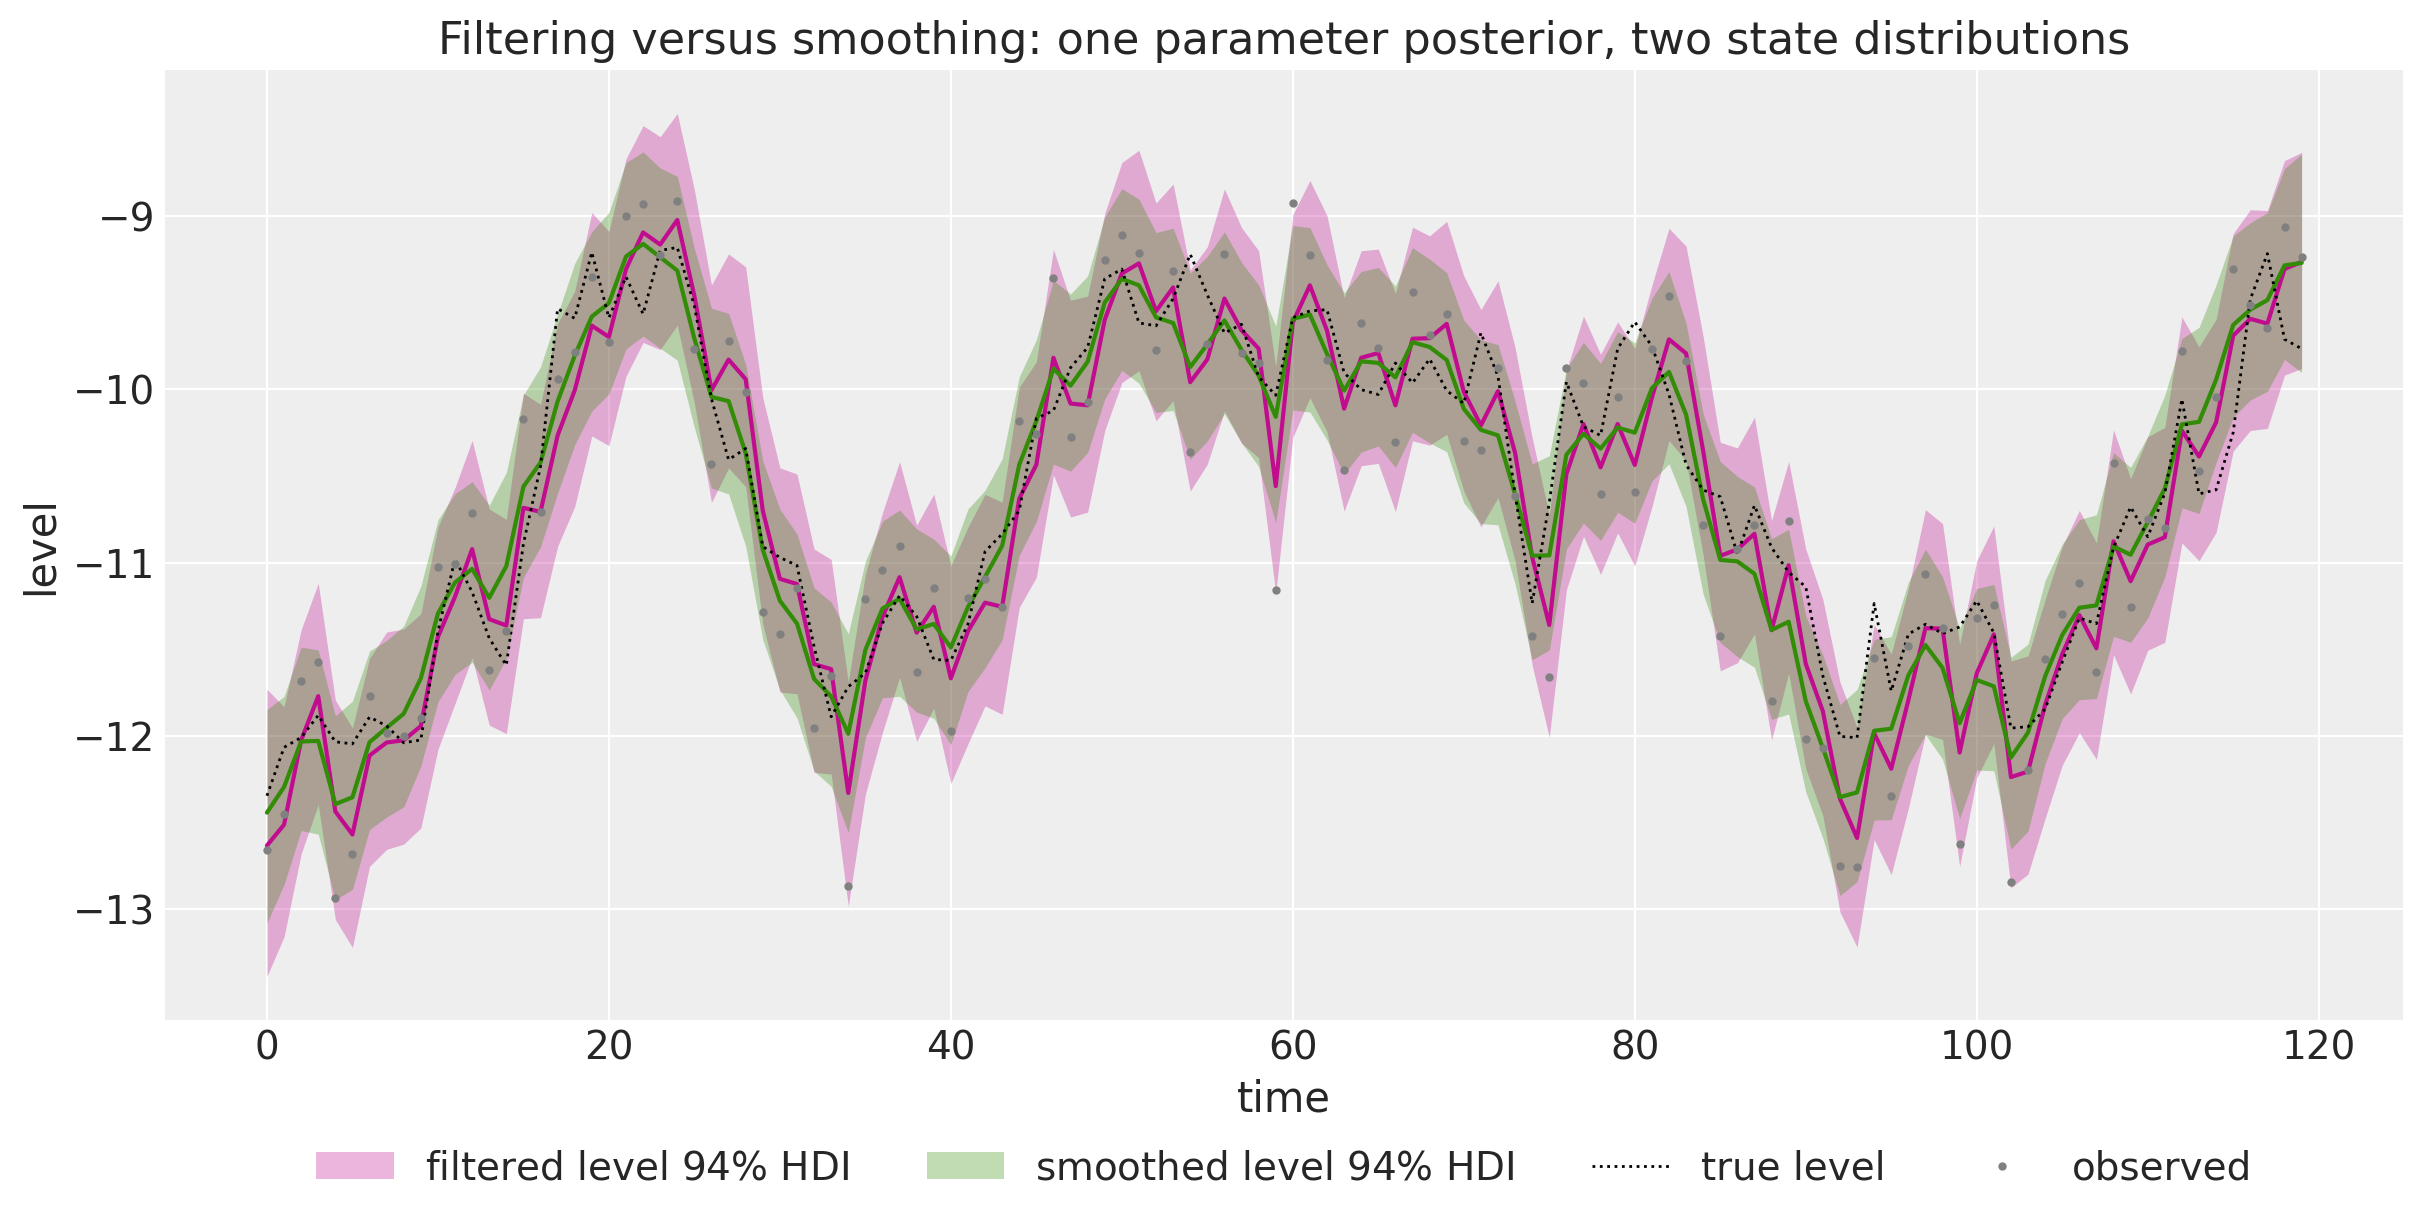

In [18]:
level_bands = {
    "filtered level": ("C3", filtered_level),
    "smoothed level": (colors["dynestyx, Kalman smoother"], levels["dynestyx, Kalman smoother"]),
}
pc = None
handles = []
for label, (color, draws) in level_bands.items():
    pc = az.plot_lm(
        predictions_to_datatree(draws, time_index[:t_obs], ["level"]),
        y="obs",
        x="t",
        plot_dim="time",
        plot_collection=pc,
        ci_kind="hdi",
        ci_prob=0.94,
        smooth=False,
        point_estimate="mean",
        visuals={
            "ci_band": {"color": color, "alpha": 0.3},
            "observed_scatter": False,
            "pe_line": {"color": color, "alpha": 1.0, "width": 1.5},
        },
        figure_kwargs={"figsize": (12, 6)},
    )
    band = pc.viz["ci_band"]["t"].item()
    band.set_label(hdi_label(0.94, prefix=f"{label} "))
    handles.append(band)
ax = pc.viz["figure"].item().axes[0]
(truth_line,) = ax.plot(
    time_index[:t_obs], x_true[:t_obs], color="black", lw=1, ls=":", label="true level"
)
(obs_points,) = ax.plot(
    time_index[:t_obs], train_data[:, 0], ".", color="gray", ms=4, label="observed"
)
handles += [truth_line, obs_points]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
ax.set(
    title="Filtering versus smoothing: one parameter posterior, two state distributions",
    xlabel="time",
    ylabel="level",
);

The filtered band is wider at every step but the last, where filtering and smoothing condition on the same observations. It is widest at the start of the window, where few observations have entered it. Its mean reacts to each new observation and lags the level. The smoothed band conditions on the whole window at every step, so it is narrower and closer to the truth. The table above confirms it with the lower RMSE and CRPS against the true level.

The three `level` sites, one per inference strategy, are all smoothing reconstructions, so we expect them to coincide.

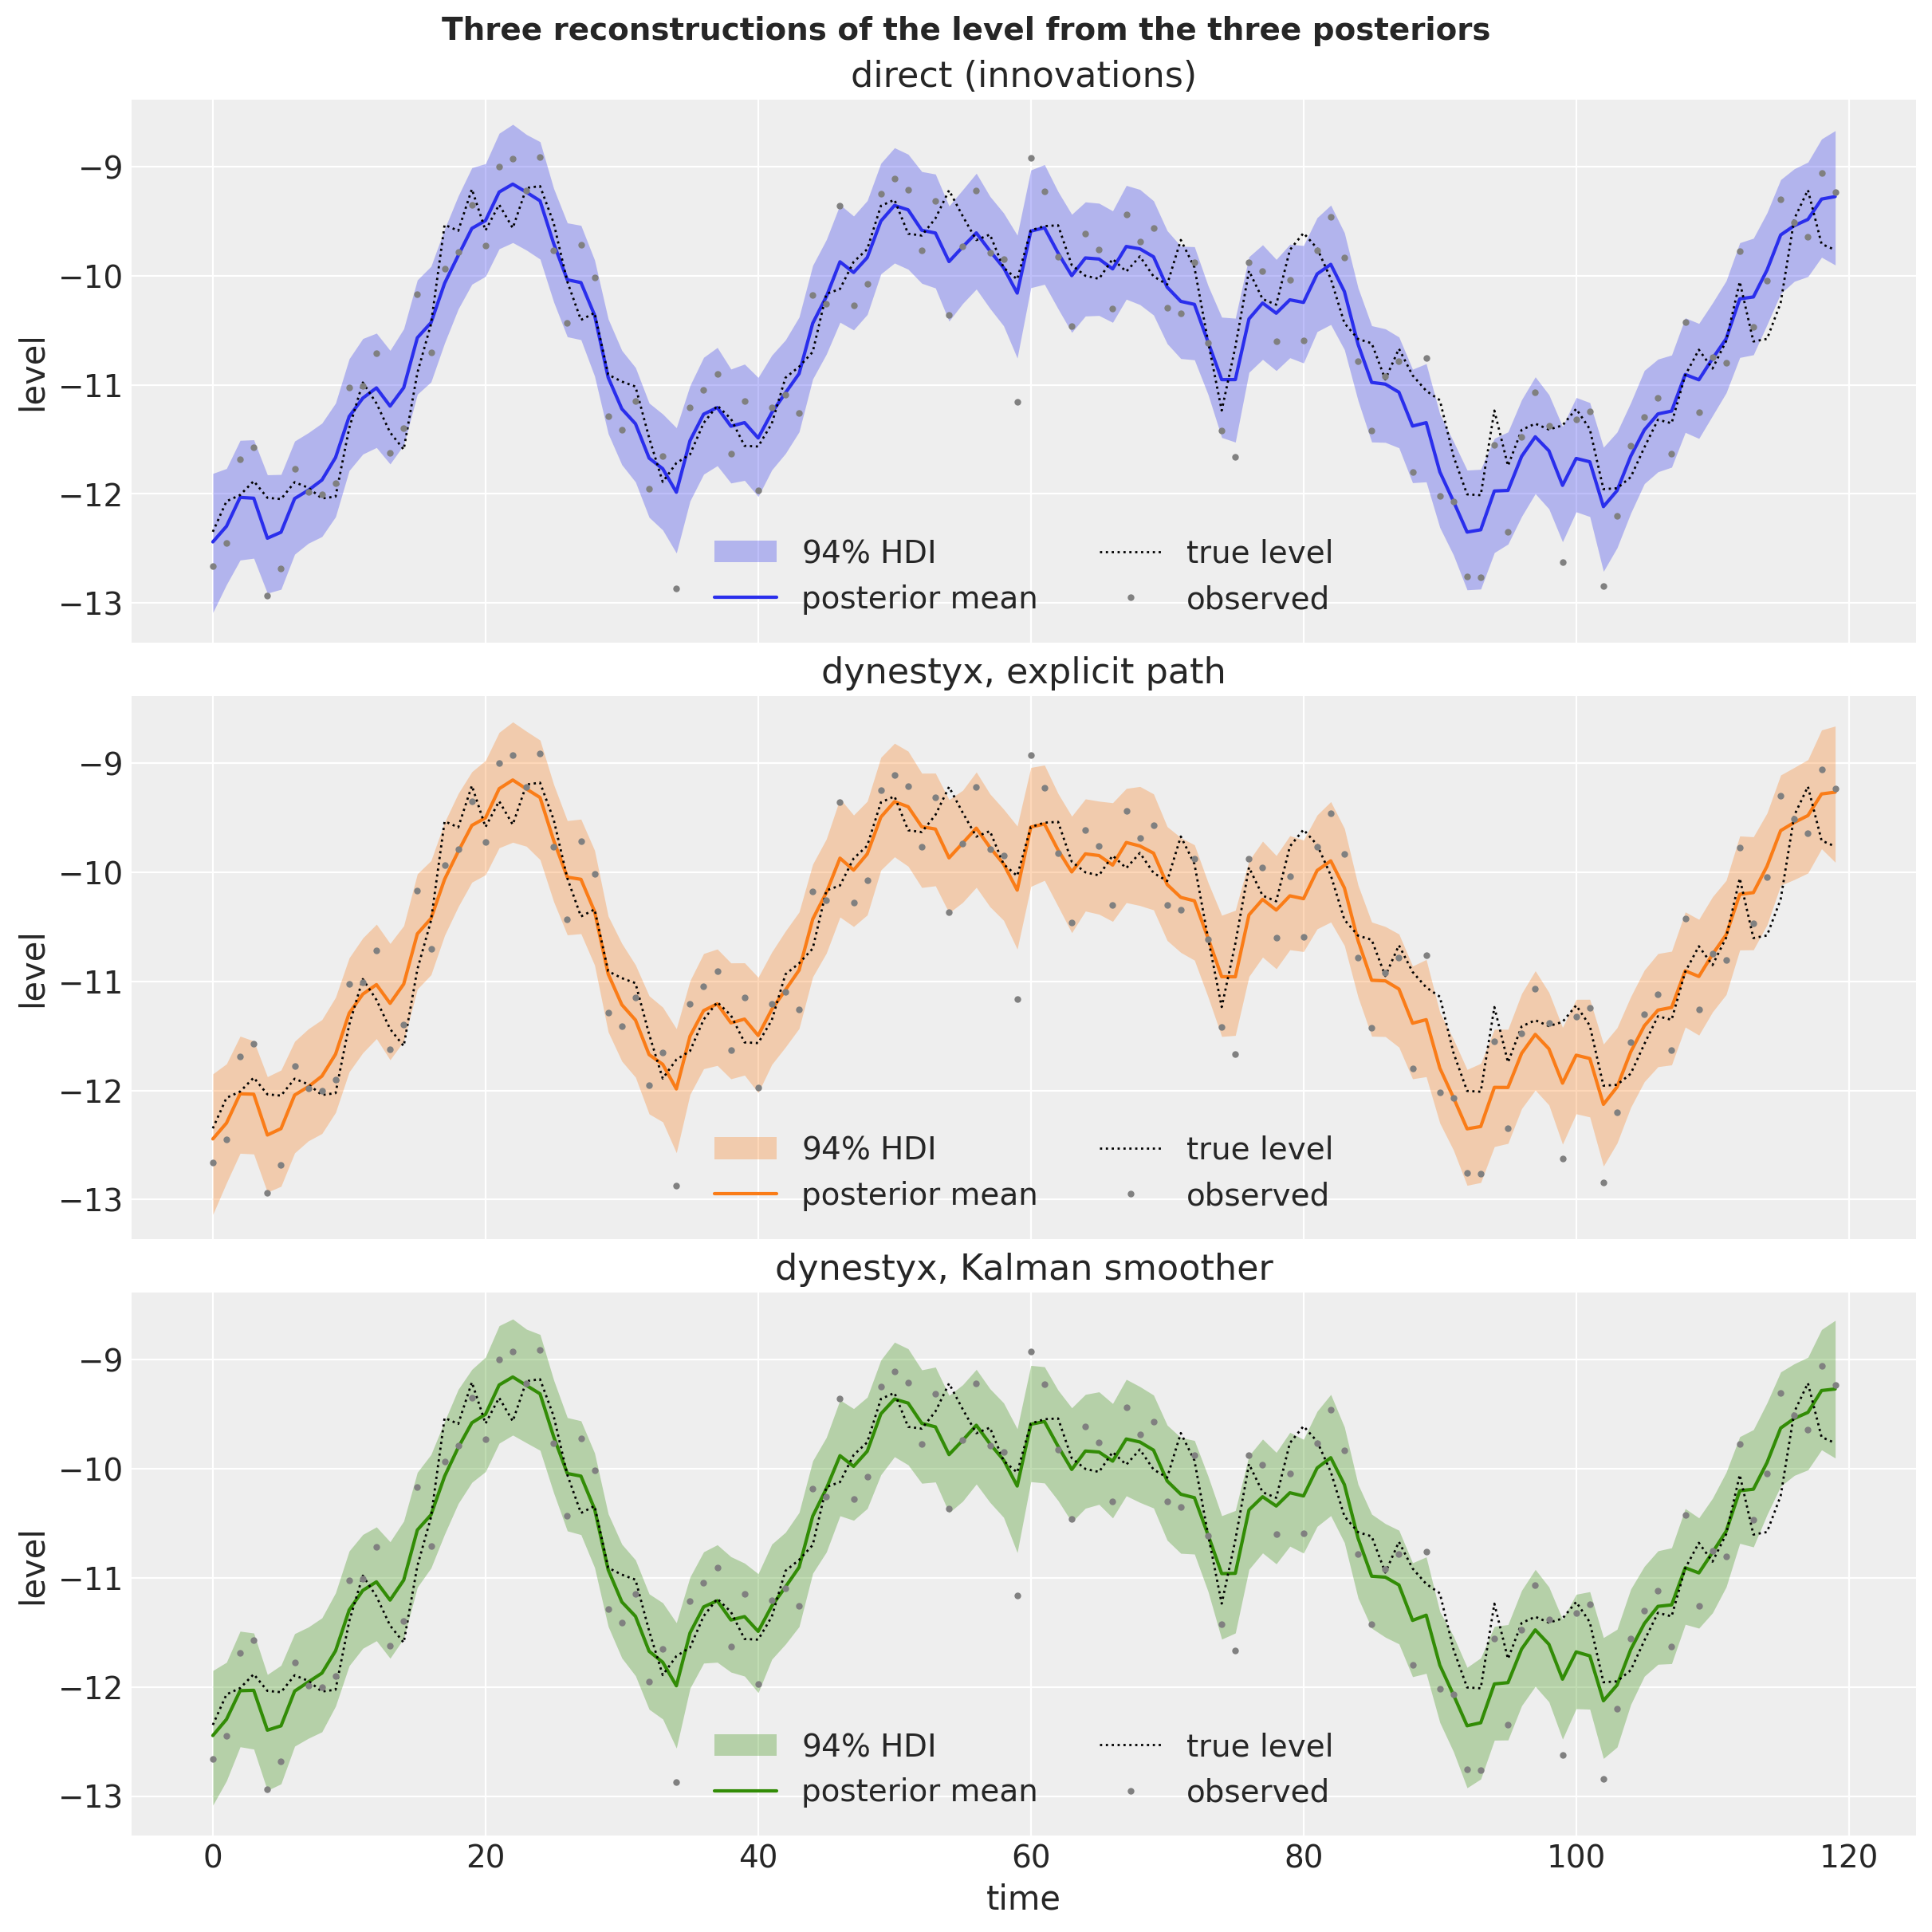

In [19]:
pc = az.plot_lm(
    predictions_to_datatree(
        np.concatenate(list(levels.values()), axis=-1), time_index[:t_obs], list(levels)
    ),
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=0.94,
    smooth=False,
    point_estimate="mean",
    col_wrap=1,
    aes={"color": ["series"]},
    aes_by_visuals={"pe_line": ["color"]},
    visuals={
        "ci_band": {"alpha": 0.3},
        "observed_scatter": False,
        "pe_line": {"alpha": 1.0, "width": 1.5},
        "xlabel": False,
        "ylabel": False,
    },
    figure_kwargs={"figsize": (12, 12), "sharex": True, "sharey": True},
)
for label in levels:
    ax = pc.get_target("t", {"series": label})
    ax.plot(time_index[:t_obs], x_true[:t_obs], color="black", lw=1, ls=":", label="true level")
    ax.plot(time_index[:t_obs], train_data[:, 0], ".", color="gray", ms=4, label="observed")
    pc.viz["ci_band"]["t"].sel(series=label).item().set_label(hdi_label(0.94))
    pc.viz["pe_line"]["t"].sel(series=label).item().set_label("posterior mean")
    ax.legend(loc="lower center", ncol=2)
    ax.set(title=label, ylabel="level")
ax.set(xlabel="time")
pc.viz["figure"].item().suptitle(
    "Three reconstructions of the level from the three posteriors", fontsize=14, fontweight="bold"
);

The three reconstructions coincide. The direct model, the explicit path built by `dynestyx` and the smoother recover the same level from the same posterior, and the two `dynestyx` models did so through the same `x_in_sample` field.

## Seasonal Regression Model

The package routes everything a model needs at prediction time through the `covariates` array, which spans the full horizon. In this example the array carries two things. The observed series sits in its first column, which the model reads back as the observed window. Fourier features fill the remaining columns, which the block forwards to `dynestyx` as control inputs (`ctrl_values`) on a time grid that covers both the observed and the predicted steps.

The seasonal pattern enters the observation equation as a regression on those features with coefficients $\beta$. With $u_t$ the row of features at step $t$:

$$
\begin{align*}
x_t &= x_{t-1} + w_t, \qquad w_t \sim \text{Normal}(0, q), \\
y_t &= x_t + \beta^\top u_t + v_t, \qquad v_t \sim \text{Normal}(0, r).
\end{align*}
$$

In `dynestyx` terms $\beta^\top u_t$ is the `D` matrix of `LTI_discrete`, which infers the control dimension from `D` since `dynestyx` $0.5.1$.

### Generate Data

We simulate the series with the same scales, the true coefficients `beta_true` and a period of $12$ steps with $2$ harmonics, again with `dsx.simulate`.

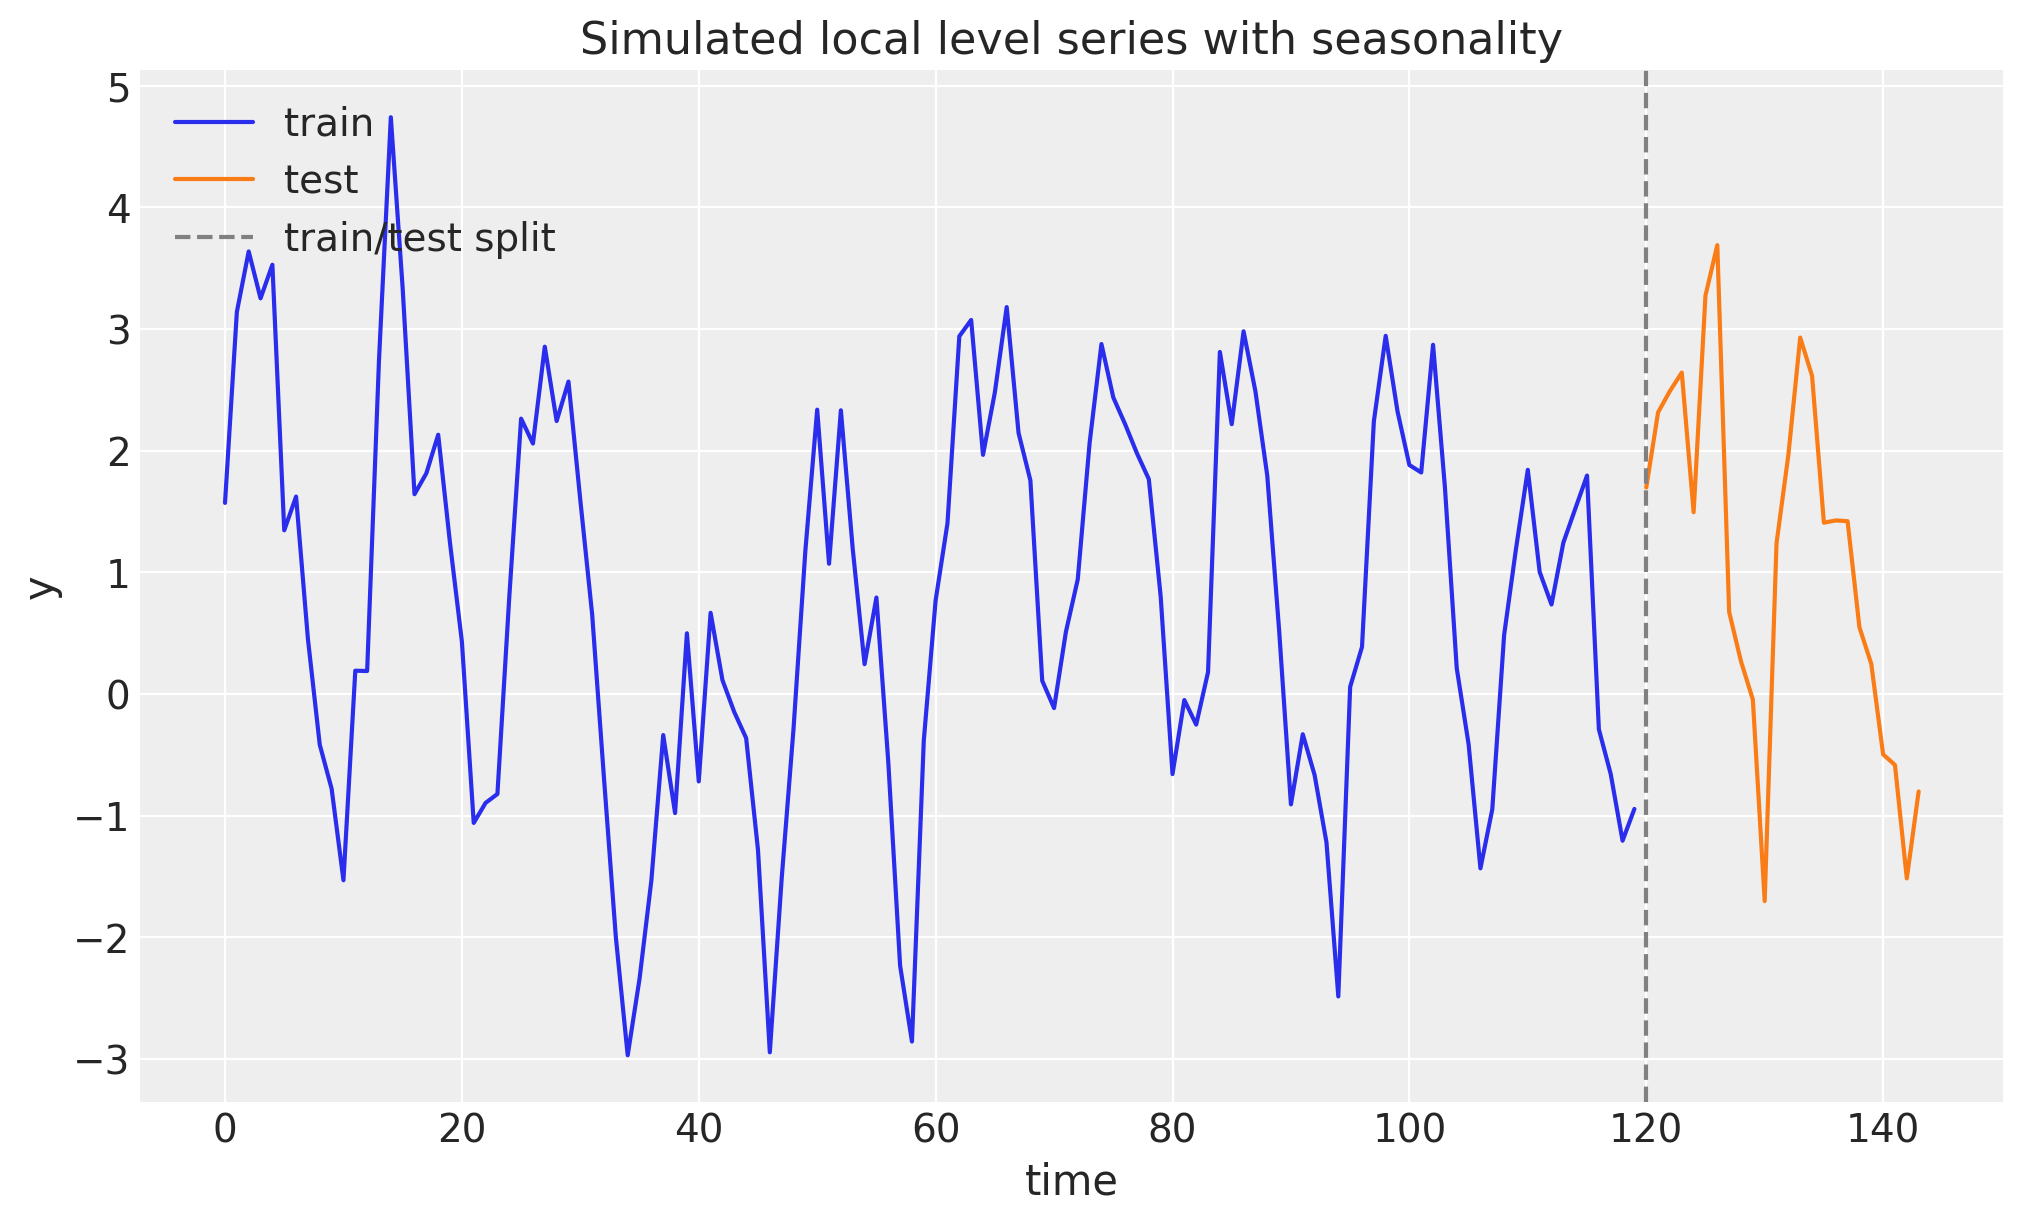

In [20]:
period, num_terms = 12.0, 2
beta_true = jnp.array([1.5, 0.5, -0.4, 0.3])
features_full = fourier_features(duration, period=period, num_terms=num_terms)  # (duration, 4)


def seasonal_level_dynamics(q: Array, r: Array, beta: Array) -> DynamicalModel:
    """Local level dynamics with a regression on the controls in the observation equation."""
    return dsx.LTI_discrete(
        A=jnp.eye(1),
        Q=jnp.eye(1) * q**2,
        H=jnp.eye(1),
        R=jnp.eye(1) * r**2,
        D=beta[None, :],
        initial_mean=jnp.zeros(1),
        initial_cov=jnp.eye(1) * 100.0,
    )


rng_key, rng_subkey = random.split(rng_key)
simulated_seasonal = dsx.simulate(
    seasonal_level_dynamics(jnp.asarray(q_true), jnp.asarray(r_true), beta_true),
    rng_key=rng_subkey,
    ctrl_times=jnp.asarray(time_grid),
    ctrl_values=features_full,
    predict_times=jnp.asarray(time_grid),
)
assert simulated_seasonal.observations is not None  # raw simulation
y_seasonal = simulated_seasonal.observations[0]  # (duration, 1)
train_seasonal, test_seasonal = y_seasonal[:t_obs], y_seasonal[t_obs:]
covariates_seasonal = jnp.concatenate([y_seasonal, features_full], axis=-1)  # (duration, 5)
covariates_seasonal_train = covariates_seasonal[:t_obs]

fig, ax = plt.subplots()
ax.plot(time_index[:t_obs], train_seasonal[:, 0], color="C0", label="train")
ax.plot(time_index[t_obs:], test_seasonal[:, 0], color="C1", label="test")
ax.axvline(t_obs, color="gray", linestyle="--", label="train/test split")
ax.legend(loc="upper left")
ax.set(title="Simulated local level series with seasonality", xlabel="time", ylabel="y");

The seasonal pattern is visible on top of the moving level.

### Model Specification

The model splits the covariate array into the observed window and the controls, adds a $\text{Normal}(0, 1)$ prior on the four coefficients, and passes the controls to the block. Every call below runs under a Kalman smoother of the same configuration as before.

In [21]:
def seasonal_level_ssm(covariates: Array, data: Array | None = None) -> None:
    """Local level plus seasonal regression model as a dynestyx state space model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :1]  # the observed series is the first column
    controls = covariates[..., 1:]  # the Fourier features span the full horizon
    q = numpyro.sample("q", dist.HalfNormal(1.0))
    r = numpyro.sample("r", dist.HalfNormal(1.0))
    beta = numpyro.sample("beta", dist.Normal(0.0, 1.0).expand([controls.shape[-1]]).to_event(1))
    state_space(h, "f", y, seasonal_level_dynamics(q, r, beta), controls=controls)


seasonal_smoother = Smoother(smoother_config=KFSmootherConfig(filter_source="cd_dynamax"))

### Model Fitting

Variational inference is the other standard path in the package, and it works on the `dynestyx` model without changes. `AutoNormal` puts a mean-field Gaussian on the six unconstrained parameters and `Trace_ELBO` includes the smoother's factor.

Because the level is integrated out, the guide does not have to approximate a $t_{\text{obs}}$-dimensional latent path, which is where mean-field guides usually underestimate uncertainty. We draw the posterior with [`draw_posterior`](../../reference/predictive.draw_posterior.html) and forecast as before. The smoother goes around `draw_posterior` too, because the guide runs the model again to compute its deterministic sites.

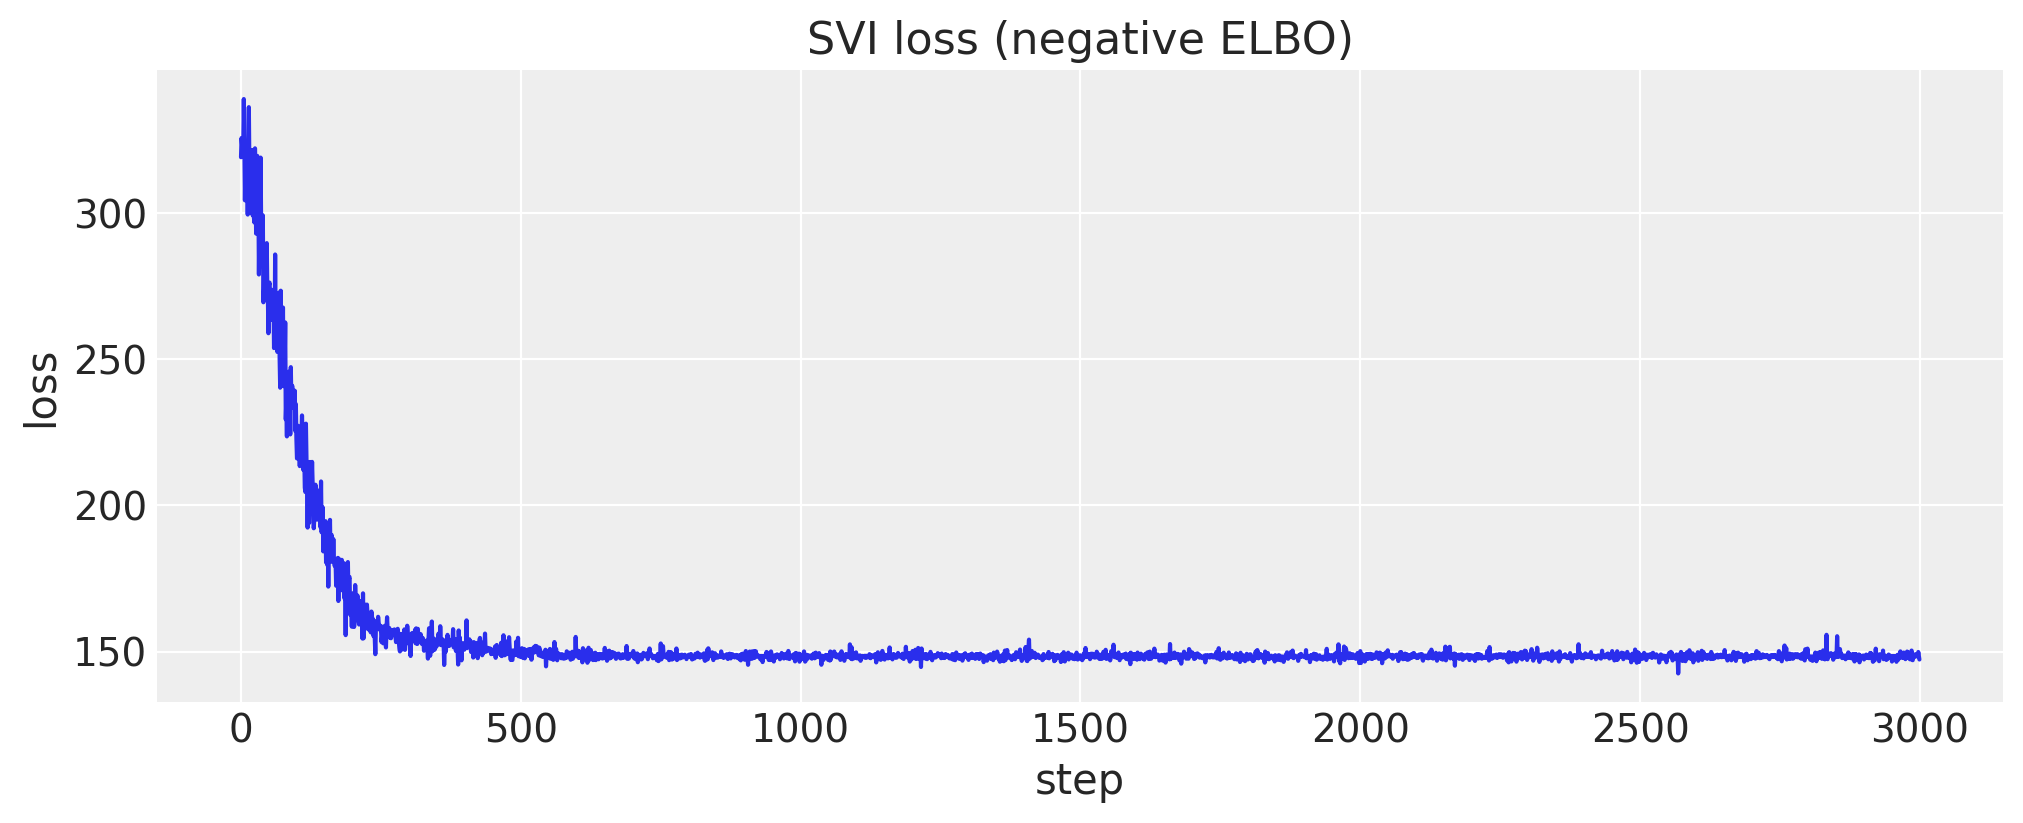

In [22]:
guide = AutoNormal(seasonal_level_ssm)
svi = SVI(seasonal_level_ssm, guide, Adam(step_size=0.01), Trace_ELBO())

rng_key, rng_subkey = random.split(rng_key)

with seasonal_smoother:
    svi_result = svi.run(
        rng_subkey, 3_000, covariates_seasonal_train, train_seasonal, progress_bar=False
    )

rng_key, key_post, key_pred = random.split(rng_key, 3)

with DiscreteTimeSimulator(n_simulations=1), seasonal_smoother:
    posterior_svi = draw_posterior(key_post, guide, svi_result.params, num_samples=2_000)
    forecast_svi = forecast(
        key_pred, seasonal_level_ssm, posterior_svi, train_seasonal, covariates_seasonal
    )

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.asarray(svi_result.losses), color="C0")
ax.set(title="SVI loss (negative ELBO)", xlabel="step", ylabel="loss");

The loss flattens well before the $3{,}000$ steps. We compare the posterior mean of `beta` with the true coefficients.

In [23]:
pl.DataFrame(
    {
        "coefficient": [f"beta[{i}]" for i in range(beta_true.shape[0])],
        "posterior mean": np.asarray(posterior_svi["beta"]).mean(axis=0),
        "posterior sd": np.asarray(posterior_svi["beta"]).std(axis=0),
        "truth": np.asarray(beta_true),
    }
).with_columns(pl.col(pl.Float32, pl.Float64).round(2))

coefficient,posterior mean,posterior sd,truth
str,f32,f32,f32
"""beta[0]""",1.68,0.13,1.5
"""beta[1]""",0.54,0.09,0.5
"""beta[2]""",-0.38,0.13,-0.4
"""beta[3]""",0.23,0.08,0.3


The truth lies within about two posterior standard deviations of each posterior mean.

### Forecast

The SVI forecast of the test window, with its $50\%$ and $94\%$ HDI bands:

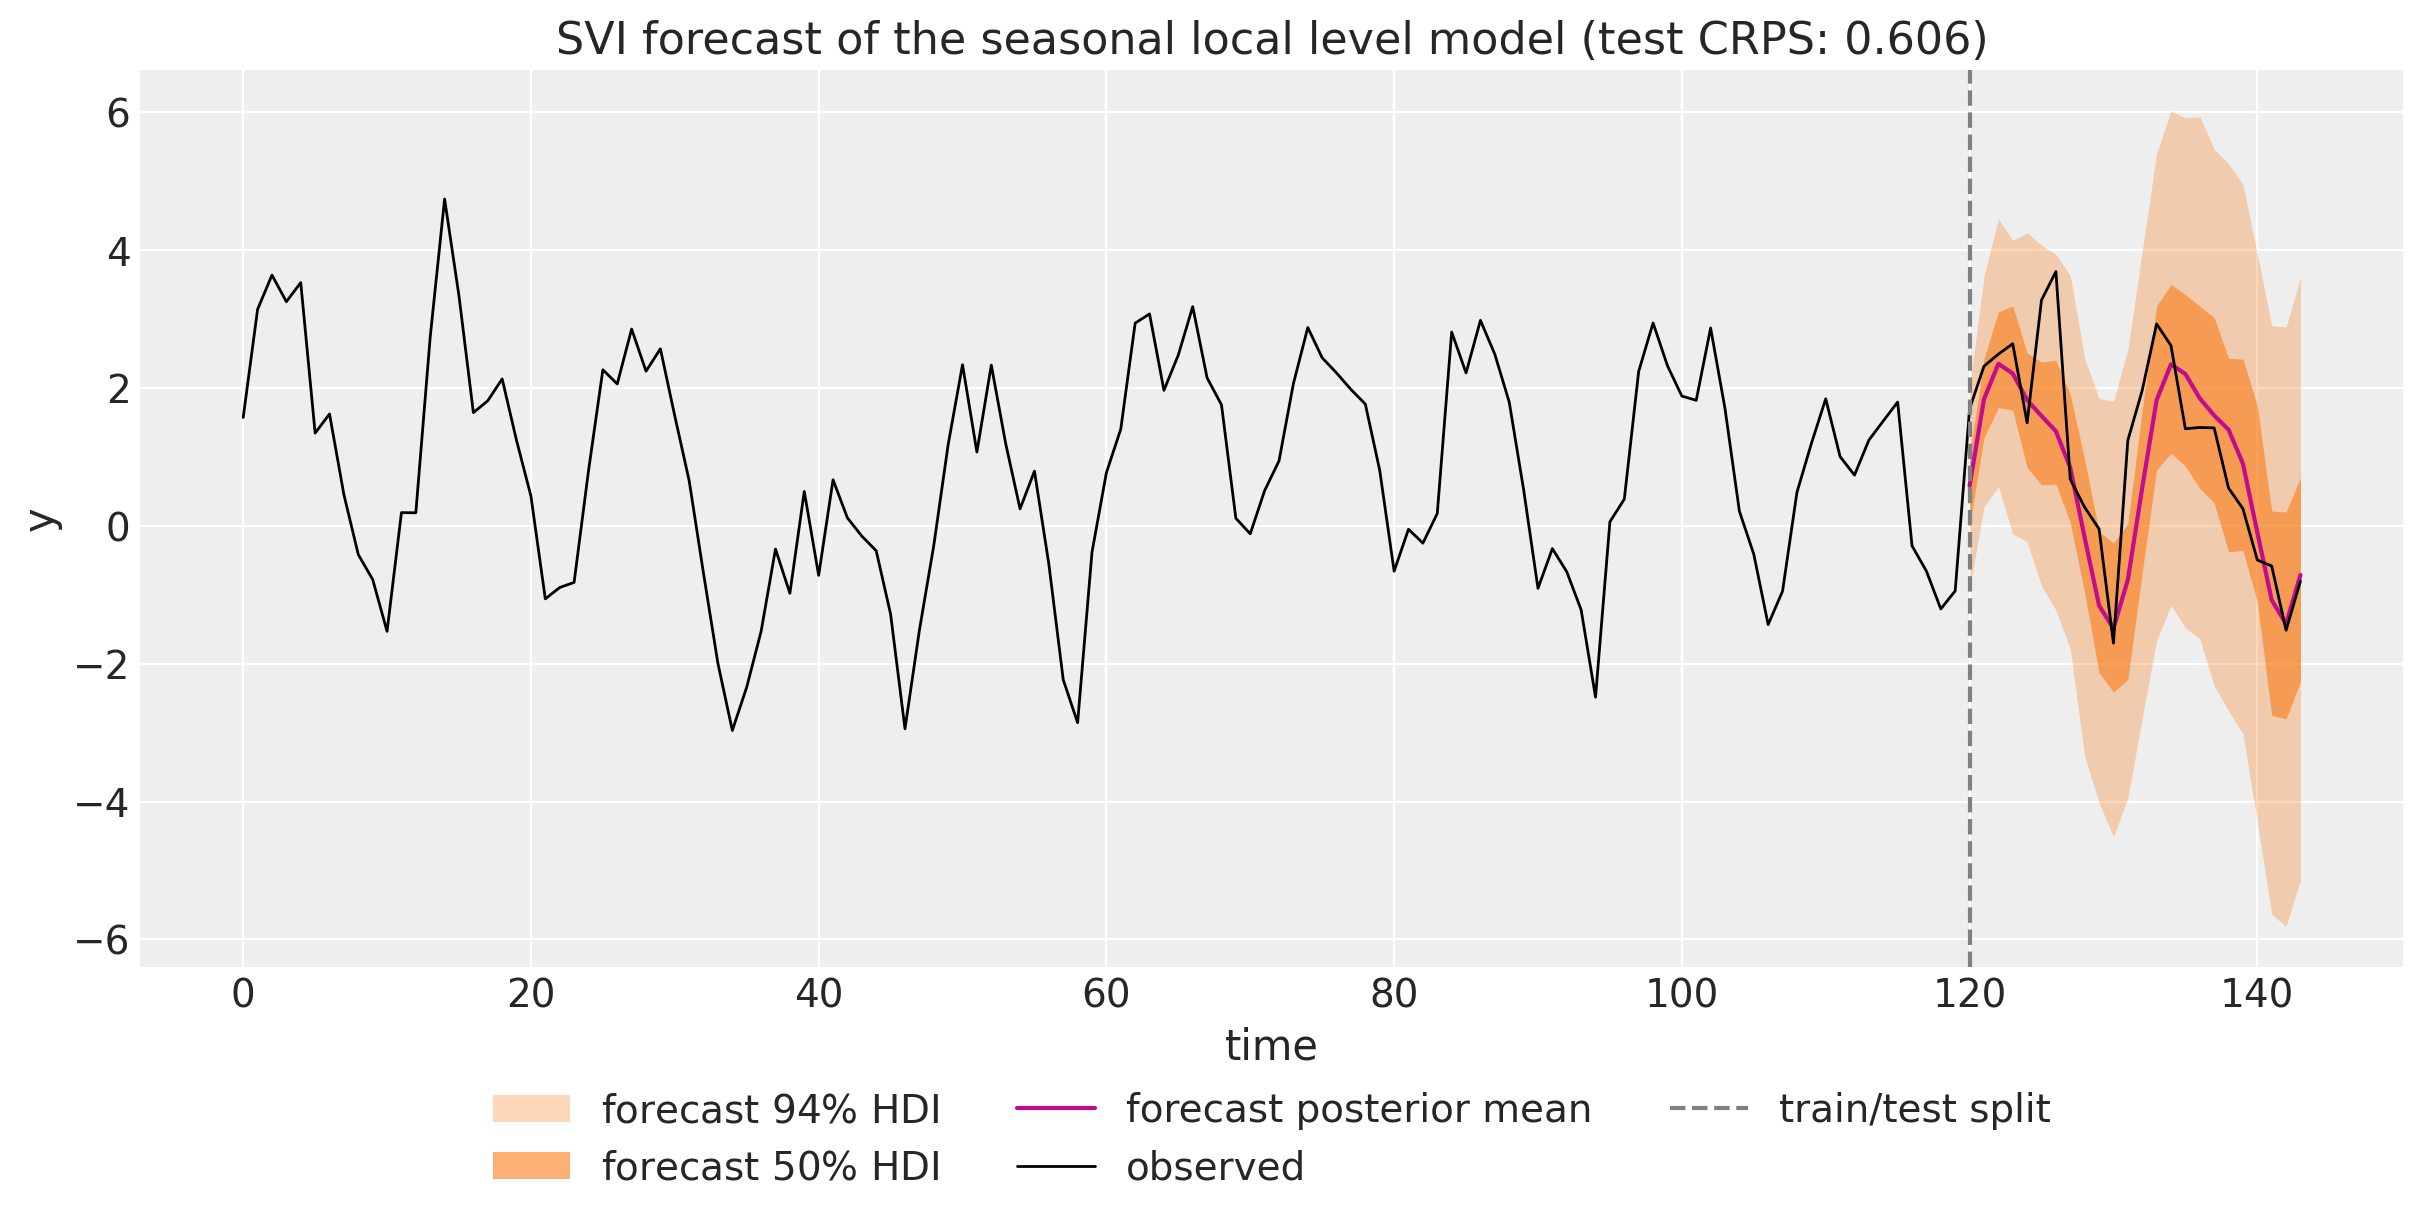

In [24]:
idata_forecast = predictions_to_datatree(
    forecast_svi, future_index.astype(float), ["y"], observed=test_seasonal
)
pc = az.plot_lm(
    idata_forecast,
    y="obs",
    x="t",
    plot_dim="time",
    ci_kind="hdi",
    ci_prob=hdi_probs,
    smooth=False,
    aes={"alpha": ["prob"]},
    alpha=hdi_alphas,
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C1"},
        "observed_scatter": False,
        "pe_line": {"color": "C3", "alpha": 1.0, "width": 1.5},
    },
    figure_kwargs={"figsize": (12, 6)},
)
bands = pc.viz["ci_band"]["t"]
band_94, band_50 = bands.sel(prob=0.94).item(), bands.sel(prob=0.5).item()
band_94.set_label(hdi_label(0.94, prefix="forecast "))
band_50.set_label(hdi_label(0.5, prefix="forecast "))
pe_line = pc.viz["pe_line"]["t"].item()
pe_line.set_label("forecast posterior mean")
ax = pc.viz["figure"].item().axes[0]
(obs_line,) = ax.plot(
    time_index, np.asarray(y_seasonal[:, 0]), color="black", lw=1, label="observed"
)
split_line = ax.axvline(t_obs, color="gray", linestyle="--", label="train/test split")
ax.legend(
    handles=[band_94, band_50, pe_line, obs_line, split_line],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
)
crps_svi = eval_crps(forecast_svi, test_seasonal)
ax.set(
    title=f"SVI forecast of the seasonal local level model (test CRPS: {crps_svi:.3f})",
    xlabel="time",
    ylabel="y",
);

The forecast follows the seasonal pattern into the test window, and the bands widen with the horizon, as the steps of the random walk add up.

### Expanding-Window Backtest

A single split scores one held-out window. [`backtest`](../../reference/evaluate.backtest.html) moves the train/test boundary forward, refits from scratch and forecasts the next window, so every later part of the series is scored out of sample once.

The loop delegates fitting and forecasting to two closures we write. `forecast_fn` fits the model with NUTS on the fold's training window and passes the draws to `forecast`. `in_sample_fn` does the same and passes them to `predict_in_sample`, so that with `eval_train=True` every fold is also scored in sample.

The `dynestyx` model needs no adapter for any of this. It is a `numpyro_forecast` model, and the closures are the same ones the other examples use. The handlers go around the `backtest` call: the smoother serves the fits of every fold and the in-sample predictive, and the simulator the forecasts. We size the folds at $12$ steps (`test_window=12`, `stride=12`) and seed the first training window with the first $72$ observations, which gives six folds.

In [25]:
def fit_fold(
    rng_key: Array, model: ForecastModel, train_data: Array, train_covariates: Array
) -> dict:
    """NUTS on one fold: 2 chains of 500 warmup and 500 draws, flattened."""
    mcmc, _ = fit_nuts(
        rng_key, model, train_data, train_covariates, num_chains=2, num_warmup=500, num_samples=500
    )
    return mcmc.get_samples()


def forecast_fn(
    rng_key: Array,
    model: ForecastModel,
    train_data: Array,
    train_covariates: Array,
    full_covariates: Array,
    num_samples: int,
    *,
    batch_size: int | None = None,
) -> Array | np.ndarray:
    """Fit ``model`` on the training window with NUTS and forecast the test horizon."""
    key_fit, key_fc = random.split(rng_key)
    fold_posterior = fit_fold(key_fit, model, train_data, train_covariates)
    return forecast(
        key_fc, model, fold_posterior, train_data, full_covariates, batch_size=batch_size
    )


def in_sample_fn(
    rng_key: Array,
    model: ForecastModel,
    train_data: Array,
    train_covariates: Array,
    num_samples: int,
    *,
    batch_size: int | None = None,
) -> Array | np.ndarray:
    """Fit ``model`` on the training window with NUTS and score its in-sample fit."""
    key_fit, key_pred = random.split(rng_key)
    fold_posterior = fit_fold(key_fit, model, train_data, train_covariates)
    return predict_in_sample(
        key_pred, model, fold_posterior, train_covariates, batch_size=batch_size
    )


backtest_metrics = {
    "crps": eval_crps,
    "coverage_50": partial(eval_coverage, alpha=0.5),
    "coverage_94": partial(eval_coverage, alpha=0.94),
}

rng_key, rng_subkey = random.split(rng_key)
with DiscreteTimeSimulator(n_simulations=1), seasonal_smoother:
    results = backtest(
        rng_subkey,
        lambda: seasonal_level_ssm,
        y_seasonal,
        covariates_seasonal,
        forecast_fn=forecast_fn,
        in_sample_fn=in_sample_fn,
        metrics=backtest_metrics,
        test_window=12,
        stride=12,
        min_train_window=72,
        num_samples=1_000,  # 2 chains x 500 draws, what fit_fold returns
        eval_train=True,
        keep_predictions=True,
    )
pl.from_pandas(results_to_dataframe(results)).with_columns(pl.col(pl.Float32, pl.Float64).round(3))

t0,t1,t2,num_samples,walltime,metric_crps,metric_coverage_50,metric_coverage_94,train_metric_crps,train_metric_coverage_50,train_metric_coverage_94
i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64
0,72,84,1000,5.198,0.678,0.25,1.0,0.214,0.722,1.0
0,84,96,1000,5.286,0.925,0.417,0.833,0.205,0.726,1.0
0,96,108,1000,5.619,0.4,0.917,1.0,0.209,0.74,1.0
0,108,120,1000,5.931,0.426,0.667,1.0,0.209,0.741,1.0
0,120,132,1000,6.052,0.66,0.583,0.917,0.201,0.758,1.0
0,132,144,1000,6.745,0.766,0.25,1.0,0.241,0.72,1.0


Every fold reports its window, its out-of-sample scores and, with `eval_train=True`, its in-sample scores. Overlaying the out-of-sample forecast of every fold on the series gives the rolling-origin view. Each band starts where its training window ends, and the dashed lines mark the successive splits.

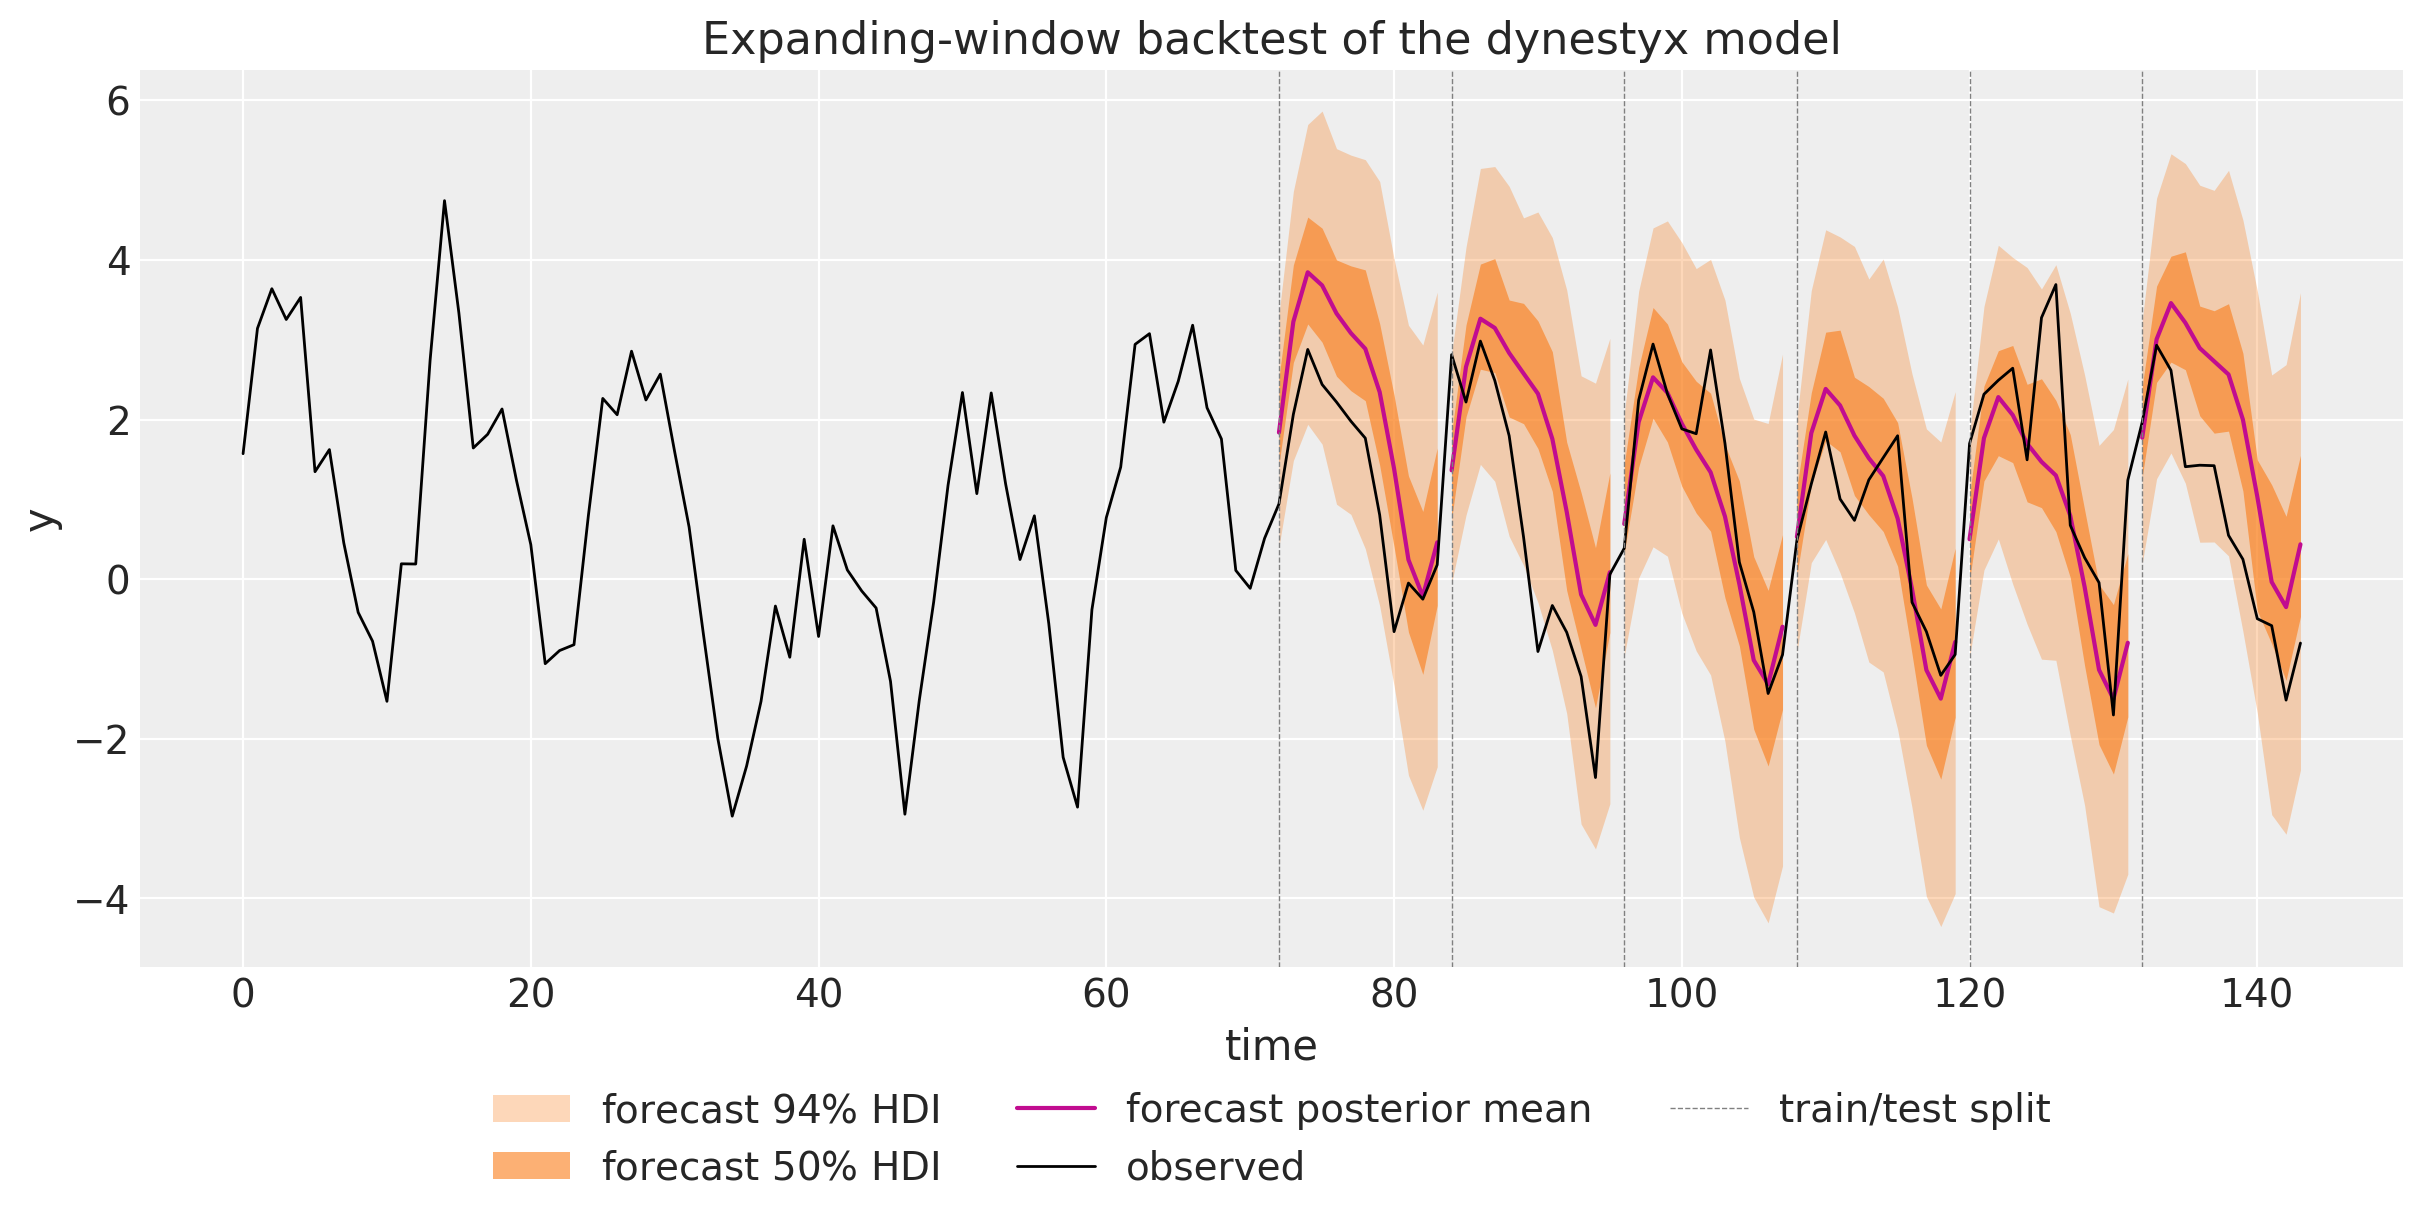

In [26]:
pc = None
for r in results:
    prediction = r.prediction
    if prediction is None:  # keep_predictions=True guarantees this never triggers
        continue
    fold_time = time_index[r.t1 : r.t2].astype(float)
    idata_fold = predictions_to_datatree(
        prediction, fold_time, ["y"], observed=y_seasonal[r.t1 : r.t2]
    )
    if pc is None:
        pc = az.plot_lm(
            idata_fold,
            y="obs",
            x="t",
            plot_dim="time",
            ci_kind="hdi",
            ci_prob=hdi_probs,
            smooth=False,
            aes={"alpha": ["prob"]},
            alpha=hdi_alphas,
            point_estimate="mean",
            visuals={
                "ci_band": {"color": "C1"},
                "observed_scatter": False,
                "pe_line": {"color": "C3", "alpha": 1.0, "width": 1.5},
            },
            figure_kwargs={"figsize": (12, 6)},
        )
        bands = pc.viz["ci_band"]["t"]
        band_94, band_50 = bands.sel(prob=0.94).item(), bands.sel(prob=0.5).item()
        pe_line = pc.viz["pe_line"]["t"].item()
    else:
        az.plot_lm(
            idata_fold,
            y="obs",
            x="t",
            plot_dim="time",
            plot_collection=pc,
            ci_kind="hdi",
            ci_prob=hdi_probs,
            smooth=False,
            point_estimate="mean",
            visuals={
                "ci_band": {"color": "C1"},
                "observed_scatter": False,
                "pe_line": {"color": "C3", "alpha": 1.0, "width": 1.5},
            },
        )

if pc is None:
    msg = "no folds were plotted"
    raise ValueError(msg)
ax = pc.viz["figure"].item().axes[0]
band_94.set_label(hdi_label(0.94, prefix="forecast "))
band_50.set_label(hdi_label(0.5, prefix="forecast "))
pe_line.set_label("forecast posterior mean")
(obs_line,) = ax.plot(
    time_index, np.asarray(y_seasonal[:, 0]), color="black", lw=1, label="observed"
)
split_lines = [
    ax.axvline(r.t1, color="gray", ls="--", lw=0.5, label="train/test split") for r in results
]
ax.legend(
    handles=[band_94, band_50, pe_line, obs_line, split_lines[0]],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
)
ax.set(title="Expanding-window backtest of the dynestyx model", xlabel="time", ylabel="y");

The bands track the series across all six folds. Finally, we look at the per-fold scores.

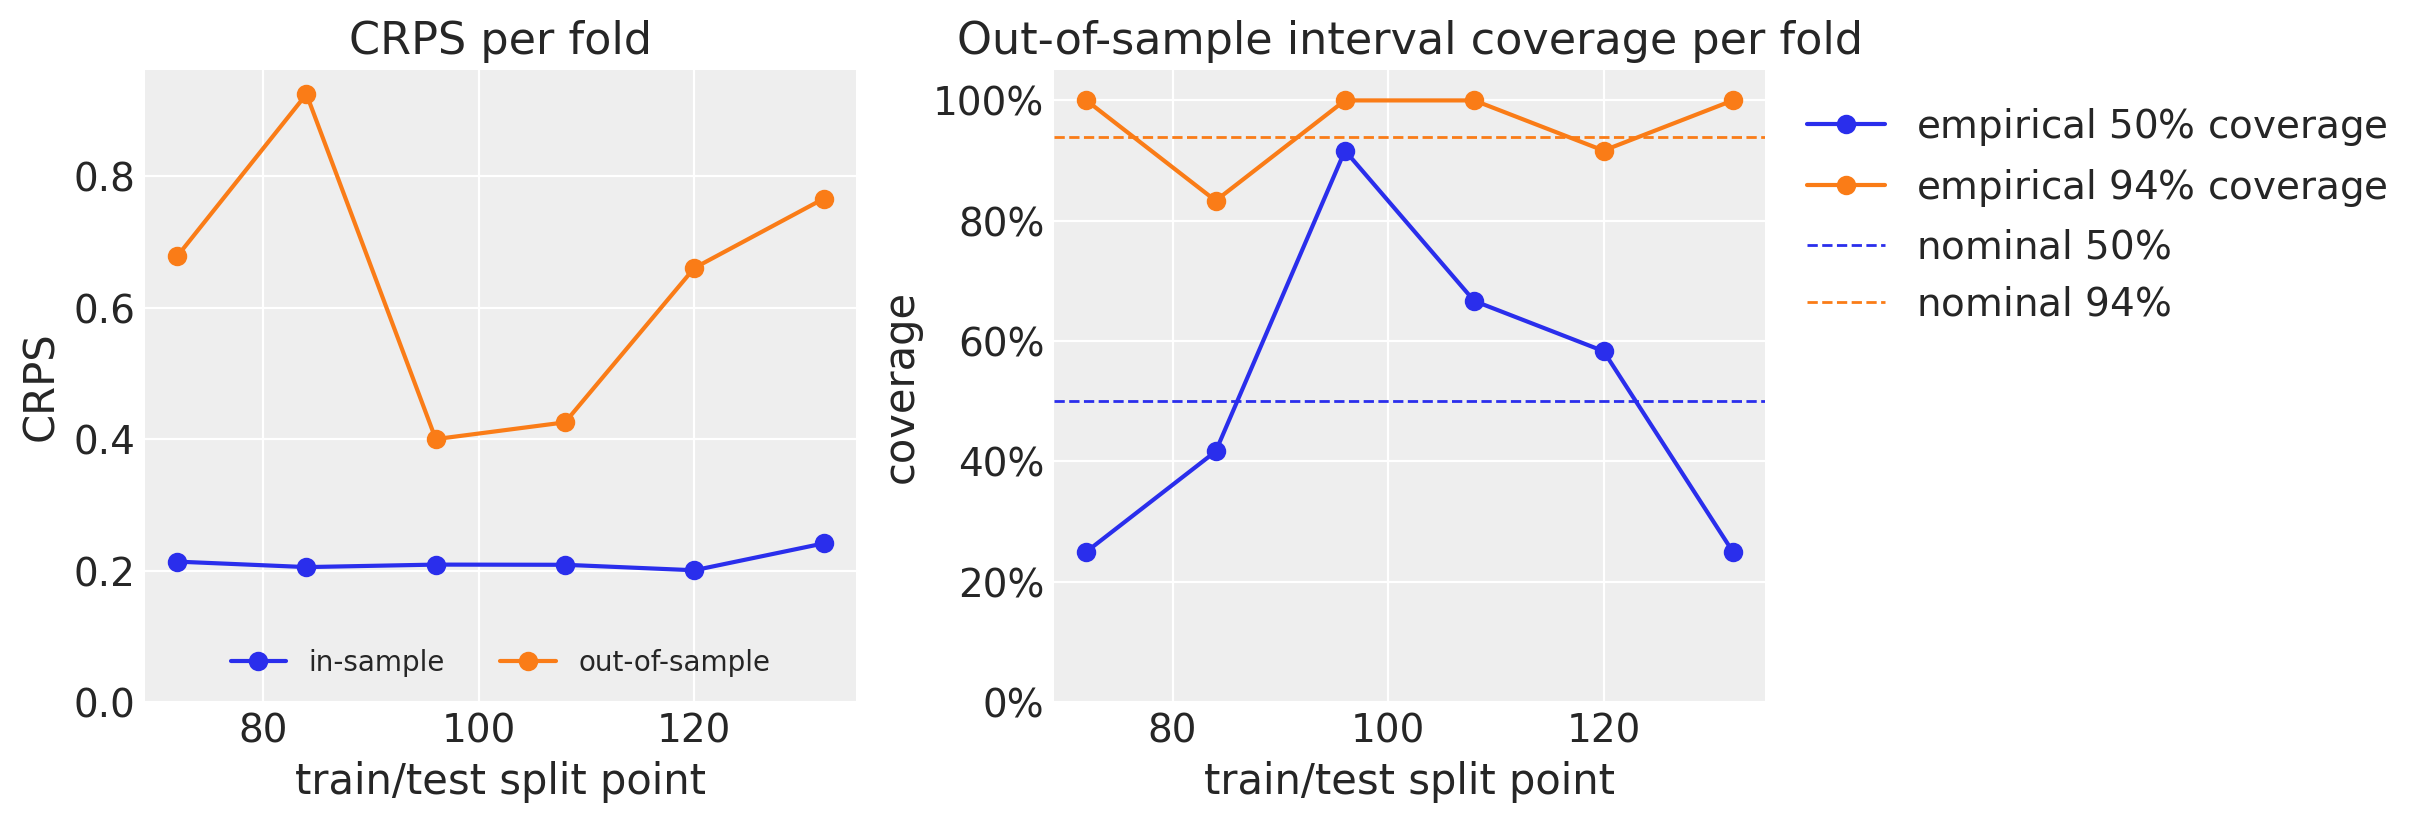

In [27]:
split_points = [r.t1 for r in results]
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), layout="constrained")
axes[0].plot(
    split_points,
    [r.train_metrics["crps"] for r in results],
    "o-",
    color="C0",
    label="in-sample",
)
axes[0].plot(
    split_points,
    [r.metrics["crps"] for r in results],
    "o-",
    color="C1",
    label="out-of-sample",
)
axes[0].legend(loc="lower center", ncol=2, fontsize="medium")
axes[0].set(xlabel="train/test split point", ylabel="CRPS", title="CRPS per fold", ylim=(0, None))
axes[1].plot(
    split_points,
    [r.metrics["coverage_50"] for r in results],
    "o-",
    color="C0",
    label=r"empirical $50\%$ coverage",
)
axes[1].plot(
    split_points,
    [r.metrics["coverage_94"] for r in results],
    "o-",
    color="C1",
    label=r"empirical $94\%$ coverage",
)
axes[1].axhline(0.5, color="C0", ls="--", lw=1, label=r"nominal $50\%$")
axes[1].axhline(0.94, color="C1", ls="--", lw=1, label=r"nominal $94\%$")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[1].set(
    xlabel="train/test split point",
    ylabel="coverage",
    title="Out-of-sample interval coverage per fold",
    ylim=(0, 1.05),
);

The in-sample CRPS is stable across folds and well below the out-of-sample CRPS, as expected for a smoothing predictive that has seen the observations it scores.

The out-of-sample CRPS varies more from fold to fold, because each fold scores only $12$ observations and the level of the series can drift away from the forecast within a window.

The empirical coverage of the central $50\%$ interval moves around the nominal level from fold to fold, and the $94\%$ interval covers at least $10$ of the $12$ observations in every fold. With $12$ observations per fold each observation moves the coverage by about $8$ percentage points ($1/12$), so this variation is expected.

## Conclusion

### Key Findings

- **One block, one handler.** A `dynestyx` model becomes a `numpyro_forecast` model through `state_space`, and the handler around each call is the inference strategy. A `Smoother` (or `Filter`) integrates the latent path out, a `LatentPathBuilder` samples it explicitly, and switching between them changes the handler, not the model.
- **The drivers work without changes.** The block owns the likelihood and registers the horizon rollout as `"forecast"` and the in-sample predictive as `"obs"`. `forecast`, `predict_in_sample`, `to_datatree`, `backtest` (in and out of sample) and the metrics work on it under the same `jit` and `vmap` as for every other model, with the `dynestyx` handlers around the call.
- **The three strategies agree.** On the local level model the posteriors, the forecasts, the in-sample bands and the reconstructed level coincide across the direct model, the explicit path and the smoother.
- **The smoother is the efficient choice.** On linear-Gaussian models it is exact, and the sampler explores the parameters only. It needs a small fraction of the gradient evaluations of the direct model for a larger effective sample size, and the smoothing distribution gives the in-sample predictive without a second fit. The backward pass makes a full evaluation more expensive than a filter evaluation, but it does not enter the gradient of the marginal log likelihood, so the smoother and the filter cost the same per gradient here.

### Model Limitations

- A `Smoother` or a `LatentPathBuilder` predicts at or after the end of the window only. (A `Filter` also predicts inside the window, from the filtering distribution.) The in-sample predictive therefore comes from the conditioned distributions and not from a rollout. Under a `Smoother` it is a per-step marginal, so a functional of the whole path would need backward simulation; the `LatentPathBuilder` gives joint paths.
- Under a `Filter` the block has no in-sample predictive. Use a `Smoother` instead: it reports the same marginal log likelihood, so the two handlers share the parameter posterior. They do not share the distribution over the states. The filtering distribution uses the observations up to step $t$, the smoothing distribution uses the whole window, and the smoothed level is the better reconstruction of the true state.
- The block uses the step index as its time grid, so it does not cover irregularly spaced observations or continuous-time dynamics. It models one series per model function, with no batch dimensions.
- Every call that runs the model needs the handler around it, including `svi.run` and `draw_posterior`, and the block raises an error without one. A `LatentPathBuilder` around a driver must be the instance that fitted the model.
- The `ssoe` family of the package (exponential smoothing in innovations form) has no stochastic latent to integrate out. With a single source of error, its state is a deterministic function of the past observations, so its likelihood is exact given the parameters and the initial values. A linear member of the family can still be written as a linear-Gaussian state space model, where the Kalman filter also integrates out the initial values: the [getting started example](dynestyx_getting_started.html) does this for ARMA(1,1). Its members that are Markov in the observations (autoregressions) can also be written with `DiracIdentityObservation` under a `LatentPathBuilder`, see the design document.

### Recommendations

1. Use a `Smoother` with `KFSmootherConfig(filter_source="cd_dynamax")` on linear-Gaussian models, and switch to `filter_source="cuthbert"` when you need missing observations, time-varying parameters or a GPU on long series.
2. Use a `LatentPathBuilder` when the path itself is the object of interest, the observation model is non-Gaussian, or the window has missing observations.
3. Put `LocScaleReparam` on the direct model in any comparison, as we did here.
4. Create the `dynestyx` handlers once, outside the model, and use one `LatentPathBuilder` per fitted model. Pass the KF configurations explicitly: `Filter()` defaults to an ensemble Kalman filter and `Smoother()` to an extended Kalman smoother on the `cuthbert` backend. These are approximate or needlessly expensive on a linear-Gaussian model.

## Next Steps

1. **Continuous-time dynamics.** A mean-reverting level on irregularly spaced observations, with a `Discretizer`, is the case `dynestyx` supports and the index-based blocks of the package cannot express. The block would need a time grid argument for it. The design document records the recipe and the caveats that keep it out of this notebook for now.
2. **Nonlinear and non-Gaussian models.** The approximate filters and smoothers of `dynestyx` (ensemble, extended, unscented and particle) extend the block beyond the linear-Gaussian case. The particle filter gives an unbiased likelihood estimate and therefore pseudo-marginal inference; the ensemble, extended and unscented Kalman filters give biased Gaussian approximations.
3. **Missing observations.** `NaN` values in the window are supported by the `cuthbert` backend for the Kalman and ensemble Kalman filters and smoothers, and by the `LatentPathBuilder`. The [getting started example](dynestyx_getting_started.html) fits through a gap with the builder. The other building blocks of the package have no missing-data support.

## References

- Waxman, D., Batenkov, D., Feser, J., Zane, A., Bingham, E., Marzouk, Y., & Levine, M. E. (2026). [*Dynestyx: A Probabilistic Programming Library for Dynamical Systems*](https://arxiv.org/abs/2606.16985).
- [`dynestyx` documentation](https://basisresearch.github.io/dynestyx/stable/), in particular the tutorials on [filtering and the marginal likelihood](https://basisresearch.github.io/dynestyx/stable/tutorials/gentle_intro/03_filtering_mll/) and on [discrete-time smoothing](https://basisresearch.github.io/dynestyx/stable/tutorials/gentle_intro/09_discrete_smoothing/).
- Durbin, J., & Koopman, S. J. (2012). *Time Series Analysis by State Space Methods*, 2nd edition. Oxford University Press.
- Särkkä, S., & Svensson, L. (2023). [*Bayesian Filtering and Smoothing*](https://users.aalto.fi/~ssarkka/pub/bfs_book_2023_online.pdf), 2nd edition. Cambridge University Press.
- [Design document: integrating `numpyro_forecast` with `dynestyx`](https://github.com/juanitorduz/numpyro_forecast/blob/main/docs/dev/dynestyx_integration_design.md), the internal design record. Its status note explains how the `contrib` block differs from the `conditioner` design that the rest of the document describes.